[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/09.%20Text%20Processing%20and%20Multiclass%20Classification/ch09_text_processing_multiclass.ipynb)

# Chapter 9: Text Processing and Multiclass Classification

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 9, pp. 236–273

**What you will learn in this chapter:**
- How raw text is turned into numbers: tokenisation, bag-of-words counts (`CountVectorizer`) and TF-IDF weights (`TfidfVectorizer`)
- How to extract richer features from text: n-grams, part-of-speech (POS) tags and (a simple proxy for) named entities
- How to train and compare Naive Bayes, SVM and logistic regression text classifiers — and why their *default* settings under-fit TF-IDF features
- How one-vs-rest (OvR) and one-vs-one (OvO) strategies turn a binary classifier into a multiclass one
- How to evaluate a text classifier: precision, recall, F1, the confusion matrix, confidence intervals and cross-validation
- Practical exercises: preprocessing and vectorising text, n-gram features, and a multiclass classifier

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Introduction to text processing | Count how often each word occurs in each document (a sparse document-term matrix) | `CountVectorizer` |
| Text vectorization techniques | Bag of Words vs TF-IDF (down-weight words that occur in many documents) | `CountVectorizer`, `TfidfVectorizer` |
| Feature extraction from text | n-grams keep local word order; POS tags add grammar | `ngram_range`, `nltk.pos_tag` |
| Text classification models | Linear models on sparse TF-IDF: Naive Bayes, SVM, logistic regression | `MultinomialNB`, `SVC`, `LogisticRegression` |
| Multiclass strategies | One classifier per class (OvR) or per pair of classes (OvO) | `OneVsRestClassifier`, `OneVsOneClassifier` |
| Evaluating text models | Precision / recall / F1, confusion matrix | `classification_report`, `confusion_matrix` |
| Practical exercises | Preprocess + vectorise, n-grams, multiclass classifier | — |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, a verification against the numbers and figures printed in the book, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text or code is inaccurate or incomplete are flagged with **Book correction** (collected again at the end).
The book's snippets omit some imports (`matplotlib`, `train_test_split`, `pandas`, …); they are added here.

**Data.** All text comes from the NLTK corpora used by the book: `movie_reviews` (2,000 reviews, positive/negative), `reuters` (10,788 newswire stories) and `brown` (500 documents in 15 genres). The first cell downloads them (about 20 MB, once).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import nltk
from IPython.display import display

# the corpora and taggers used in this chapter (quiet: prints nothing; skipped if already present)
for resource in ["movie_reviews", "reuters", "brown", "stopwords", "punkt_tab", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

print("scikit-learn version:", sklearn.__version__)
print("NLTK version        :", nltk.__version__)
print("NumPy version       :", np.__version__)

scikit-learn version: 1.9.1
NLTK version        : 3.10.3
NumPy version       : 2.5.3


## 1. Introduction to text processing

**Summary.** Most of the world's data is text, and computers cannot read it: a model needs numbers. *Text processing* converts raw documents into a numeric matrix. The simplest representation is **Bag of Words**: split every document into **tokens** (words), build a **vocabulary** of all tokens seen in the training set, and count how often each token occurs in each document.
A collection of documents is called a **corpus**. Here the corpus is NLTK's `movie_reviews` (2,000 reviews labelled `neg` / `pos`).

### Getting ready

In [2]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import movie_reviews
import matplotlib.pyplot as plt     # missing from the book's imports (needed for the plot below)

In [3]:
try:
    movie_reviews.sents()
except LookupError:
    nltk.download('movie_reviews')

In [4]:
documents = []
labels = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append(movie_reviews.raw(fileid))
        labels.append(category)

In [5]:
label_map = {
    label: i for i,
    label in enumerate(sorted(list(set(labels))))
}
numerical_labels = [
    label_map[label] for label in labels
]

In [6]:
# Using a smaller subset for demonstration purposes
# to speed up processing
# and reduce memory usage,
# as the full movie_reviews corpus is quite large.
# You can adjust subset_size or
# remove this sampling for full dataset usage.
subset_size = 500 # Using 500 samples for quicker demonstration
if len(documents) > subset_size:
    # Stratified sampling to maintain class proportions
    texts_subset, _, labels_subset, _ = train_test_split(
        documents, numerical_labels,
        train_size=subset_size,
        stratify=numerical_labels,
        random_state=2024
    )
else:
    texts_subset = documents
    labels_subset = numerical_labels
X_train, X_test, y_train, y_test = train_test_split(
    texts_subset, labels_subset,
    test_size=0.3, random_state=2024,
    stratify=labels_subset
)
print("reviews:", len(documents), "| label map:", label_map, "| class counts:", np.bincount(numerical_labels))
print("subset :", len(texts_subset), "| train / test:", len(X_train), "/", len(X_test))
print("\n--- first 300 characters of one review ---")
print(X_train[0][:300])

reviews: 2000 | label map: {'neg': 0, 'pos': 1} | class counts: [1000 1000]
subset : 500 | train / test: 350 / 150

--- first 300 characters of one review ---
starting with the little mermaid and most recently the lion king , the walt disney company once again proved that they could not only consistently make modern day animated classics , but were particularly in touch with what the general viewing public--particularly kids-- wanted to see . 
therefore ,


**Verification against the book:** the corpus has 2,000 reviews (1,000 `neg` + 1,000 `pos`); the book samples 500 and splits them 350 / 150 ✔. (The code that follows is the book's, with its comments, verbatim.)

### How to do it…
The book's two steps: fit a `CountVectorizer` with English stop-word removal on the **training** texts only, then `transform` the test texts with the *same* vocabulary.

> *Stop words* are very frequent words (the, a, an, …) that carry little information for tasks such as classification.

In [7]:
vectorizer = CountVectorizer(stop_words='english')
X_train_vect = vectorizer.fit_transform(X_train)

In [8]:
X_test_vect = vectorizer.transform(X_test)

print("train matrix:", X_train_vect.shape, "(documents x vocabulary)   type:", type(X_train_vect).__name__)
print("test  matrix:", X_test_vect.shape, "  <- same 18,881 columns: the vocabulary comes from the training set only")
nnz = X_train_vect.nnz
total = X_train_vect.shape[0] * X_train_vect.shape[1]
print(f"non-zero entries: {nnz:,} of {total:,} ({nnz/total:.2%}) -> stored sparsely; a dense float64 copy would need {total*8/1e6:.0f} MB")

train matrix: (350, 18881) (documents x vocabulary)   type: csr_matrix
test  matrix: (150, 18881)   <- same 18,881 columns: the vocabulary comes from the training set only
non-zero entries: 89,870 of 6,608,350 (1.36%) -> stored sparsely; a dense float64 copy would need 53 MB


### How it works…
`CountVectorizer` converts text into a **sparse matrix of token counts**: one row per document, one column per unique token (the vocabulary). A *token* is the basic unit of text — here a word (it could also be a sentence or a character).
The book visualises the counts with a horizontal bar chart and says it shows "the top 20 tokens":

```python
feature_names = vectorizer.get_feature_names_out()
counts = X_train_vect.toarray().sum(axis=0)
plt.figure(figsize=(10,6))
plt.barh(feature_names, counts, color='skyblue')
plt.xlabel('Count')
plt.title('Token Frequency in Training Data')
plt.show()
```

> **Book correction (the printed code does not draw the book's figure).** This code passes the *entire* vocabulary to `barh`, i.e. **18,881 bars** (one per token, in alphabetical order), not 20, and the title differs from the one in Figure 9.1 ("Top 20 Token Frequencies in Training Data"). It also lacks `import matplotlib.pyplot as plt`.
> Figure 9.1 was made after selecting the 20 largest counts, which is what the cell below does (the code above is shown, not executed, because an 18,881-bar chart is unreadable).

the book's code would draw 18881 bars


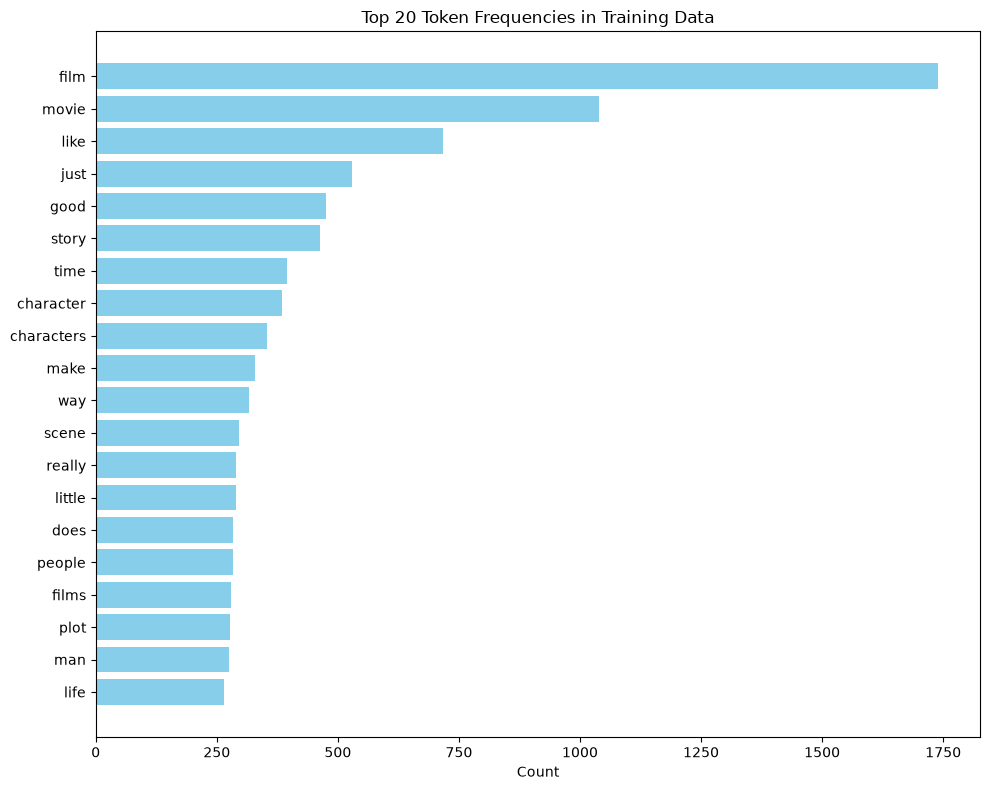

[('film', 1739), ('movie', 1039), ('like', 717), ('just', 530), ('good', 475), ('story', 464), ('time', 396), ('character', 384), ('characters', 354), ('make', 328)]


In [9]:
feature_names = vectorizer.get_feature_names_out()
counts = X_train_vect.toarray().sum(axis=0)
print("the book's code would draw", len(feature_names), "bars")

top20 = np.argsort(counts)[-20:]          # indices of the 20 largest counts (ascending, so the largest ends up on top)
plt.figure(figsize=(10, 8))
plt.barh(feature_names[top20], counts[top20], color='skyblue')
plt.xlabel('Count')
plt.title('Top 20 Token Frequencies in Training Data')
plt.tight_layout()
plt.show()

print([(feature_names[i], int(counts[i])) for i in top20[::-1][:10]])

**Verification against the book:** the bars reproduce Figure 9.1 — `film` (1,739), `movie` (1,039), `like` (717), `just`, `good`, `story`, `time`, `character`, `characters`, `make`, … down to `life` (265). "It should come as no surprise that `film` and `movie` occur most frequently" ✔.

### There's more…
The book lists further preprocessing steps — TF-IDF (Section 2), n-grams (Section 3), **stemming** and **lemmatization** — without code. Stemming chops word endings with rules (`movies → movi`), lemmatisation maps words to dictionary forms (`better → good`, needs a lexicon such as WordNet, which is not downloaded here).

**Extension — what `CountVectorizer` really does.** A toy corpus makes the mechanics visible: lower-casing, the default token pattern `(?u)\b\w\w+\b` (tokens of **two or more** characters, so `I` disappears), counts per document, and words never seen in training being ignored at transform time:

In [10]:
toy = ["The movie was great, great acting!",
       "The movie was not great.",
       "I loved the film"]
cv_toy = CountVectorizer()
M = cv_toy.fit_transform(toy)
display(pd.DataFrame(M.toarray(), columns=cv_toy.get_feature_names_out(), index=[f"doc{i}" for i in range(3)]))

new_doc = ["A brand new unseen word, but the movie was great"]
print("transform of an unseen document:", dict(zip(cv_toy.get_feature_names_out(), cv_toy.transform(new_doc).toarray()[0])))
print("-> only vocabulary words are counted; 'brand', 'new', 'unseen', 'word', 'but' are silently dropped")

,acting,film,great,loved,movie,not,the,was
doc0,1,0,2,0,1,0,1,1
doc1,0,0,1,0,1,1,1,1
doc2,0,1,0,1,0,0,1,0


transform of an unseen document: {'acting': np.int64(0), 'film': np.int64(0), 'great': np.int64(1), 'loved': np.int64(0), 'movie': np.int64(1), 'not': np.int64(0), 'the': np.int64(1), 'was': np.int64(1)}
-> only vocabulary words are counted; 'brand', 'new', 'unseen', 'word', 'but' are silently dropped


Every choice below changes the vocabulary (and therefore the model). Vocabulary size on the 350 training reviews, plus a **stemmer** built with NLTK's `PorterStemmer` (it needs no downloaded data) plugged into `CountVectorizer` as a custom `analyzer`:

In [11]:
import re
from functools import lru_cache
from nltk.stem import PorterStemmer

print([(w, PorterStemmer().stem(w)) for w in ["movies", "characters", "running", "studies", "acting", "better"]])

stem = lru_cache(maxsize=None)(PorterStemmer().stem)          # cache: each distinct word is stemmed once
token_re = re.compile(r"(?u)\b\w\w+\b")                      # the default token pattern
def stemmed_words(doc):
    return [stem(w) for w in token_re.findall(doc.lower())]

configs = {
    "default (lowercase, no stop-word removal)": CountVectorizer(),
    "stop_words='english'  (the book)":          CountVectorizer(stop_words='english'),
    "stop_words + min_df=2":                     CountVectorizer(stop_words='english', min_df=2),
    "stop_words + max_features=5000":            CountVectorizer(stop_words='english', max_features=5000),
    "Porter stemming":                           CountVectorizer(analyzer=stemmed_words),
    "no lower-casing":                           CountVectorizer(lowercase=False),
}
rows = {name: len(v.fit(X_train).vocabulary_) for name, v in configs.items()}
display(pd.Series(rows, name="vocabulary size").to_frame())

[('movies', 'movi'), ('characters', 'charact'), ('running', 'run'), ('studies', 'studi'), ('acting', 'act'), ('better', 'better')]


,vocabulary size
"default (lowercase, no stop-word removal)",19175
stop_words='english' (the book),18881
stop_words + min_df=2,9501
stop_words + max_features=5000,5000
Porter stemming,13305
no lower-casing,19175


Stop-word removal deletes only 294 vocabulary entries — but they are the most frequent words, so the matrix loses far more mass than the vocabulary does. `min_df=2` (drop words that occur in a single review) **halves** the vocabulary (19,175 → 9,501): half of all distinct words are hapax legomena (typos, names, rare words). Stemming merges inflected forms (`film`/`films`) and cuts it by 31% (→ 13,305). `lowercase=False` changes nothing because `movie_reviews` text is already lower-cased. All of these shrink or reshape the feature space without any guarantee of better accuracy — so test it.
A warning for sentiment tasks: scikit-learn's stop-word list contains **negations** (`not`, `no`, `never`), which flips the meaning of a review:

In [12]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
print(len(ENGLISH_STOP_WORDS), "stop words | 'not' in list:", "not" in ENGLISH_STOP_WORDS, "| 'no':", "no" in ENGLISH_STOP_WORDS, "| 'never':", "never" in ENGLISH_STOP_WORDS)
print("CountVectorizer(stop_words='english') on 'not good, not great':",
      CountVectorizer(stop_words='english').fit(["not good, not great"]).get_feature_names_out())

318 stop words | 'not' in list: True | 'no': True | 'never': True
CountVectorizer(stop_words='english') on 'not good, not great': ['good' 'great']


Does it matter for accuracy? A 5-fold cross-validation on all 2,000 reviews (TF-IDF + logistic regression; the vectoriser sits inside the `Pipeline`, so each fold learns its vocabulary from its own training part only):

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

docs_arr = np.array(documents, dtype=object)
cv5 = StratifiedKFold(5, shuffle=True, random_state=2024)
rows = {}
for name, vec in {"no stop-word removal": TfidfVectorizer(),
                  "stop_words='english'": TfidfVectorizer(stop_words='english'),
                  "Porter stemming": TfidfVectorizer(analyzer=stemmed_words)}.items():
    s = cross_val_score(make_pipeline(vec, LogisticRegression(max_iter=1000)), docs_arr, numerical_labels, cv=cv5)
    rows[name] = {"mean CV accuracy": s.mean(), "std over folds": s.std()}
display(pd.DataFrame(rows).T.round(3))

,mean CV accuracy,std over folds
no stop-word removal,0.824,0.013
stop_words='english',0.821,0.025
Porter stemming,0.832,0.012


The three variants are within about one standard error of each other (≈ 0.009 for 2,000 documents): on this corpus, stop-word removal and stemming change the vocabulary a lot but the accuracy very little.

### Theory — from text to a design matrix
* **Pipeline:** raw string → *tokenise* → *normalise* (lower-case, strip accents, stem) → *filter* (stop words, rare words) → *count*. `CountVectorizer` does all of it with `lowercase`, `token_pattern`, `stop_words`, `min_df`/`max_df`, `max_features`, `ngram_range` and `analyzer`.
* **Bag-of-Words assumption:** order and grammar are discarded; a review is just a multiset of words. Cheap, surprisingly strong for topic/sentiment tasks, blind to negation and context (Section 3 adds n-grams).
* **Sparsity:** a document uses ~1% of the vocabulary, so the matrix is a `scipy.sparse` CSR matrix (values + column indices). Always keep it sparse: densifying 350 × 18,881 already costs 53 MB, the 5,394 × 22,864 Reuters matrix almost 1 GB (Section 2).
* **`fit` vs `transform`:** the vocabulary is learned from the training set only; unseen test words are ignored. Fitting the vectoriser on all data leaks information (document frequencies) from the test set.
* **Out-of-vocabulary words** are the price of a fixed vocabulary; `HashingVectorizer` (Section 2) avoids storing one at all.

### Hands-on workflow (book)
Clone the repository, pick or build a text dataset, clean it (punctuation, case, tokenisation), vectorise with `CountVectorizer` / `TfidfVectorizer`, split, train a model (logistic regression, Naive Bayes), evaluate (accuracy, F1) and plot token frequencies. **Exercise 1** at the end of this notebook implements these steps.

## 2. Text vectorization techniques

**Summary.** Vectorisation maps text to numbers. Two classic schemes:
* **Bag of Words (BoW):** the raw count of each word in a document.
* **TF-IDF (term frequency – inverse document frequency):** the count, multiplied by a weight that is *large for words that are rare across the corpus* and small for words that occur everywhere, so distinctive words stand out.

(Before any of this, a computer needs a way to store letters at all — ASCII / Unicode encodings.) *Word embeddings* are a third family (see "There's more").

### Getting ready — the Reuters corpus
The book switches to NLTK's `reuters` corpus and classifies on each story's **first** category.

In [14]:
import numpy as np
from sklearn.feature_extraction.text import (
    CountVectorizer, TfidfVectorizer)
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import reuters

In [15]:
try:
    reuters.fileids()
except LookupError:
    nltk.download('reuters')

In [16]:
documents = reuters.fileids()
# Using the first category as the label for simplicity:
texts = [reuters.raw(doc_id) for doc_id in documents]
labels = [reuters.categories(doc_id)[0] for doc_id in documents]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.5, random_state=2024)

n_multi = sum(len(reuters.categories(d)) > 1 for d in documents)
print("documents:", len(documents), "| train / test:", len(X_train), "/", len(X_test))
print("categories in the corpus:", len(reuters.categories()), "| distinct first-categories used as labels:", len(set(labels)))
print("documents with more than one category:", n_multi, f"({n_multi/len(documents):.1%}) -> using only the first one throws information away")
print("words in the corpus:", f"{len(reuters.words()):,}")
print("\nlargest classes:", pd.Series(labels).value_counts().head(5).to_dict())

documents: 10788 | train / test: 5394 / 5394
categories in the corpus: 90 | distinct first-categories used as labels: 79
documents with more than one category: 1628 (15.1%) -> using only the first one throws information away


words in the corpus: 1,720,901

largest classes: {'earn': 3926, 'acq': 2369, 'crude': 552, 'interest': 453, 'money-fx': 362}


> **Book correction (description of the corpus).** The book says the corpus has "approximately 1.3 million words with over 90 possible topics". Counted here: **1,720,901 words** and **exactly 90** categories (of which only 79 occur as a *first* category). 1,628 documents carry several categories, which is why the "first category" shortcut loses information (multilabel classification is shown in Section 5).
> The label distribution is also very skewed: `earn` alone is ~36% of the documents.

### How to do it…
Two vectorisers on the same training texts: `CountVectorizer` (BoW) and `TfidfVectorizer`.

In [18]:
bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

In [19]:
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("BoW   :", X_train_bow.shape, "| dtype", X_train_bow.dtype, "| max count in one cell:", X_train_bow.max())
print("TF-IDF:", X_train_tfidf.shape, "| dtype", X_train_tfidf.dtype, "| row norms (L2):", np.round(np.sqrt(X_train_tfidf[:5].multiply(X_train_tfidf[:5]).sum(axis=1)).A.ravel(), 3))

BoW   : (5394, 22864) | dtype int64 | max count in one cell: 135
TF-IDF: (5394, 22864) | dtype float64 | row norms (L2): [1. 1. 1. 1. 1.]


Same shape — only the *values* differ: integer counts for BoW; real numbers in [0, 1] for TF-IDF, with every row scaled to unit L2 length.

### How it works…
* **BoW** represents texts as frequency counts of individual words, disregarding word order and grammar.
* **TF-IDF** adjusts word frequencies by the rarity of the word across documents, giving higher weights to distinctive terms.

The book visualises the TF-IDF weights: the mean TF-IDF weight of each term over all training documents (English stop words removed), top 20.

In [20]:
vis_tfidf_vectorizer = TfidfVectorizer(stop_words='english')
vis_X_train_tfidf = (
    vis_tfidf_vectorizer.fit_transform(X_train))

In [21]:
feature_names = vis_tfidf_vectorizer.get_feature_names_out()
tfidf_means = vis_X_train_tfidf.toarray().mean(axis=0)

In [22]:
N = 20

In [23]:
if len(feature_names) < N:
    N = len(feature_names)

In [24]:
# np.argsort sorts in ascending order,
# so we take the last N indices.
# These indices will correspond to the N features
# with the highest TF-IDF scores,
# sorted from the Nth highest to the 1st highest
# (suitable for plt.barh to plot highest at top).
if N > 0 :
    # Proceed only if there are features to plot
    sorted_indices_ascending = np.argsort(tfidf_means)
    top_n_plotting_indices = sorted_indices_ascending[-N:]

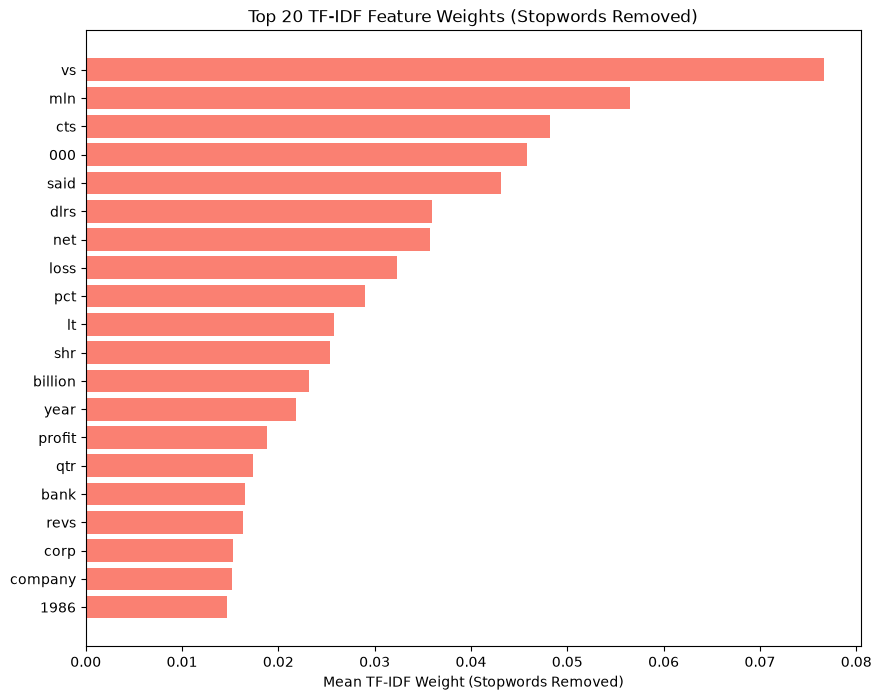

[('vs', 0.0766), ('mln', 0.0565), ('cts', 0.0482), ('000', 0.0459), ('said', 0.0431), ('dlrs', 0.036), ('net', 0.0357), ('loss', 0.0323)]


In [25]:
if N > 0:
    plot_feature_names = feature_names[
        top_n_plotting_indices]
    plot_tfidf_means = tfidf_means[
        top_n_plotting_indices]
    plt.figure(
        figsize=(10, 8)
    ) # Adjusted figsize for better readability with 20 items
    plt.barh(
        plot_feature_names,
        plot_tfidf_means, color='salmon'
    )
    plt.xlabel('Mean TF-IDF Weight (Stopwords Removed)')
    plt.title(
        f'Top {N} TF-IDF Feature Weights '
        '(Stopwords Removed)')
else:
    # Handle case with no features
    # (e.g., if all features were stopwords or N=0)
    plt.figure(
        figsize=(10, 6)
    ) # Original figsize for empty or minimal plot
    plt.barh([], []) # Plot empty data
    plt.xlabel('Mean TF-IDF Weight (Stopwords Removed)')
    plt.title(
        'TF-IDF Feature Weights '
        '(No non-stopword features to display)'
    )
plt.show()

print([(feature_names[i], round(float(tfidf_means[i]), 4)) for i in top_n_plotting_indices[::-1][:8]])

**Verification against the book:** Figure 9.2 is reproduced bar for bar — `vs` (0.077), `mln` (0.056), `cts`, `000`, `said`, `dlrs`, `net`, `loss`, `pct`, `lt`, `shr`, `billion`, `year`, `profit`, `qtr`, `bank`, `revs`, `corp`, `company`, `1986` ✔. (The printed code lost its indentation in typesetting — `if N > 0 :` and the lines under it — and was restored here.)

The book says the tokens "might look a bit odd". They are **Reuters telegraphic abbreviations**: `vs` = versus, `mln` = million, `cts` = cents, `dlrs` = dollars, `pct` = percent, `shr` = share, `qtr` = quarter, `revs` = revenues, and `lt` comes from the HTML-escaped `&lt;` that precedes every company ticker. They are typical of *earnings reports* (`earn`, 36% of the stories).

In [26]:
n_lt = sum("&lt;" in t for t in X_train)
print(f"training stories containing the escaped '&lt;': {n_lt} of {len(X_train)} ({n_lt/len(X_train):.0%})")
ex = next(t for t, y in zip(X_train, y_train) if y == "earn")
print("\n--- an 'earn' story ---\n" + ex[:300])

training stories containing the escaped '&lt;': 3006 of 5394 (56%)

--- an 'earn' story ---
TIERCO GROUP INC &lt;TIER> YEAR ENDED DEC 31 LOSS
  Shr loss 72 cts vs loss 1.57 dlr
      Net loss 1,526,359 vs loss 3,315,834
      Revs 8,032,798 vs 7,276,517
  




> **Book correction (what is being ranked).** The book says the tokens are "sorted by their weight calculated as a formula of their distinctiveness within and among documents". The plotted quantity is the **mean TF-IDF over all documents**, which favours words that are *frequent in many documents and still fairly rare* — it ranks the telegraphic jargon of the largest class, not the words that distinguish classes. To see distinctiveness you must compare **per class** (cell below).

**Extension — TF-IDF by hand.** scikit-learn's formula (with its default `smooth_idf=True`) is $\mathrm{idf}(t)=\ln\frac{1+n}{1+\mathrm{df}(t)}+1$, then $\mathrm{tfidf}=\mathrm{tf}\times\mathrm{idf}$ and each row is divided by its L2 norm. Verified on a three-document corpus:

In [27]:
docs_toy = ["the cat sat on the mat", "the dog sat on the log", "cats and dogs"]
tv = TfidfVectorizer()
T = tv.fit_transform(docs_toy).toarray()

cvt = CountVectorizer()
tf = cvt.fit_transform(docs_toy).toarray().astype(float)
n = tf.shape[0]
df = (tf > 0).sum(axis=0)
idf = np.log((1 + n) / (1 + df)) + 1
manual = tf * idf
manual = manual / np.linalg.norm(manual, axis=1, keepdims=True)

print("matches TfidfVectorizer:", np.allclose(manual, T), "| idf_ identical:", np.allclose(idf, tv.idf_))
display(pd.DataFrame({"df (docs containing it)": df.astype(object), "idf": idf.round(3).astype(object)}, index=cvt.get_feature_names_out()).T)
print("-> 'the' (in 2 of 3 documents) gets a low idf, 'cat'/'mat'/'log'/'dogs' (in 1 of 3) a high one; no word gets idf 0 because of the '+1'")

matches TfidfVectorizer: True | idf_ identical: True


,and,cat,cats,dog,dogs,log,mat,on,sat,the
df (docs containing it),1,1,1,1,1,1,1,2,2,2
idf,1.693,1.693,1.693,1.693,1.693,1.693,1.693,1.288,1.288,1.288


-> 'the' (in 2 of 3 documents) gets a low idf, 'cat'/'mat'/'log'/'dogs' (in 1 of 3) a high one; no word gets idf 0 because of the '+1'


**Extension — what makes each class stand out.** Mean TF-IDF *inside a class* minus the overall mean TF-IDF gives the words that characterise the class (stop words removed, words in ≥ 5 documents):

In [28]:
tf_s = TfidfVectorizer(stop_words='english', min_df=5)
Xs = tf_s.fit_transform(X_train)
terms = tf_s.get_feature_names_out()
y_arr = np.array(y_train)
overall = np.asarray(Xs.mean(axis=0)).ravel()

rows = {}
for cat in ["earn", "crude", "grain", "ship"]:
    class_mean = np.asarray(Xs[y_arr == cat].mean(axis=0)).ravel()
    top = np.argsort(class_mean - overall)[::-1][:8]
    rows[f"{cat} ({(y_arr == cat).sum()} docs)"] = ", ".join(terms[top])
with pd.option_context("display.max_colwidth", None):
    display(pd.Series(rows, name="most characteristic terms").to_frame())

,most characteristic terms
earn (1972 docs),"vs, cts, net, loss, 000, mln, shr, profit"
crude (256 docs),"oil, crude, opec, barrel, bpd, barrels, prices, bbl"
grain (131 docs),"wheat, tonnes, grain, usda, crop, agriculture, rice, department"
ship (87 docs),"gulf, ships, port, shipping, seamen, cargo, strike, ship"


Now the words are meaningful: oil/opec/barrels for `crude`, wheat/tonnes/corn for `grain`, vessels/port/gulf for `ship`. This is what a classifier exploits — the jargon of the overall ranking above is only characteristic of the single largest class.

**Extension — BoW vs TF-IDF as classifier input, and the cost of going dense.** The book never trains a model in this recipe, so here is the missing comparison: the same linear SVM on both representations (79 classes, first category as label).

In [29]:
from sklearn.svm import LinearSVC

import warnings
from sklearn.exceptions import ConvergenceWarning

fitted, converged = {}, {}
for name, Xtr_, kw in [("BoW counts", X_train_bow, {"max_iter": 20000}), ("TF-IDF", X_train_tfidf, {})]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fitted[name] = LinearSVC(**kw).fit(Xtr_, y_train)
    converged[name] = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
svm_bow, svm_tfidf = fitted["BoW counts"], fitted["TF-IDF"]
print("liblinear converged -> BoW counts (max_iter=20,000):", converged["BoW counts"], "| TF-IDF (default max_iter):", converged["TF-IDF"])
majority = max(set(y_test), key=list(y_test).count)
print(f"majority class ('{majority}') baseline: {np.mean(np.array(y_test) == majority):.3f}")
print(f"LinearSVC on BoW counts : test accuracy {svm_bow.score(X_test_bow, y_test):.3f}")
print(f"LinearSVC on TF-IDF     : test accuracy {svm_tfidf.score(X_test_tfidf, y_test):.3f}")

nnz = X_train_bow.nnz
sparse_mb = (X_train_bow.data.nbytes + X_train_bow.indices.nbytes + X_train_bow.indptr.nbytes) / 1e6
dense_mb = X_train_bow.shape[0] * X_train_bow.shape[1] * 8 / 1e6
print(f"\nBoW matrix: density {nnz / (X_train_bow.shape[0] * X_train_bow.shape[1]):.2%} | sparse storage {sparse_mb:.1f} MB vs {dense_mb:.0f} MB if dense")

liblinear converged -> BoW counts (max_iter=20,000): False | TF-IDF (default max_iter): True
majority class ('earn') baseline: 0.362
LinearSVC on BoW counts : test accuracy 0.883
LinearSVC on TF-IDF     : test accuracy 0.903

BoW matrix: density 0.32% | sparse storage 4.7 MB vs 987 MB if dense


(The `ConvergenceWarning` raised by `LinearSVC` on raw counts is captured instead of printed: unscaled counts of up to 135 make the optimisation slow, so the BoW model is not fully converged even after 20,000 iterations — a practical advantage of TF-IDF's bounded, normalised values.)

Both are far above the 36% majority baseline and TF-IDF is ahead, as the book's claim ("allows the classification … much more efficiently") suggests; the 2-point gap on 5,394 test stories is larger than its standard error (≈ 0.4 points), but it is one split and one model — treat it as an indication.
The sparse matrix needs 4.7 MB instead of ~1 GB.

**Another scikit-learn option the book does not mention:** `HashingVectorizer` hashes tokens straight into a fixed number of columns — no vocabulary to store or fit, constant memory, at the price of possible collisions and no way to map columns back to words.

In [30]:
from sklearn.feature_extraction.text import HashingVectorizer

hv = HashingVectorizer(n_features=2**12, alternate_sign=False)
H = hv.transform(X_train[:5])           # stateless: no fit needed
print("hashed matrix:", H.shape, "| non-zeros per document:", H.getnnz(axis=1))

hashed matrix: (5, 4096) | non-zeros per document: [222  26  59  64  36]


### There's more…
**Word embeddings** (Word2Vec, GloVe) represent each word as a dense vector (typically 50–300 numbers) in which similar words are close, capturing semantic relationships that BoW/TF-IDF cannot (they treat `film` and `movie` as unrelated columns). scikit-learn does not *train* embeddings, but vectors produced elsewhere can be averaged per document and fed to any scikit-learn model. They are also the first step inside modern LLMs.

### Theory — TF-IDF
* **tf** rewards a word that occurs often in *this* document; **idf** penalises words that occur in *many* documents; the product highlights words that are frequent here but rare elsewhere.
* **L2 normalisation** makes documents of different length comparable (the cosine similarity of two rows is then just their dot product).
* **Sparse + high-dimensional** (23,000 columns for 5,394 documents) is exactly the regime where *linear* models excel — Section 4.
* BoW keeps interpretable integer counts (and suits models such as Multinomial Naive Bayes, which assume counts); TF-IDF usually helps linear models and nearest-neighbour search.

### Hands-on workflow (book)
Pick a dataset suited to vectorisation, clean and tokenise it, apply `CountVectorizer` and `TfidfVectorizer`, split into train/test, train and evaluate models on the vectorised features, optionally try pretrained embeddings, and plot the TF-IDF weights. This is covered by Exercise 1.

## 3. Feature extraction from text

**Summary.** Beyond single words, three kinds of features enrich a text model:
* **n-grams** — sequences of *n* consecutive words, which recover some of the word order that BoW throws away (`not good`);
* **part-of-speech (POS) tagging** — the grammatical role of every word (noun, verb, adjective, …);
* **named-entity recognition (NER)** — locating and typing names of persons, organisations and places.

### Getting ready — the Brown corpus (four sentences)
The book builds a deliberately tiny dataset: the first two sentences of the first two Brown categories, so that the tagged output can be read by eye.

In [31]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import brown
from nltk.util import ngrams as nltk_ngrams
import matplotlib.pyplot as plt
from collections import Counter
import nltk
from nltk.corpus import stopwords

In [32]:
nltk.download('brown', quiet=True)
nltk.download('punkt', quiet=True)

True

In [33]:
texts = []
labels = []

In [34]:
# We'll use the first two categories from
# the Brown corpus for this example
# and take a small number of sentences from each.
# This will create a small dataset suitable for demonstration.
categories_to_use = brown.categories()[:2] # Example:
                                           # ['adventure',
                                           #  'belles_lettres']
num_sents_per_category = 2 # Number of sentences to extract
                           # from each category
for i, category in enumerate(categories_to_use):
    # Get sentences for the current category
    # brown.sents() returns a list of sentences,
    # where each sentence is a list of tokens.
    category_sents = brown.sents(categories=category)
    # Take the specified number of sentences
    # from the beginning of the list
    for sent_tokens in category_sents[
        :num_sents_per_category
    ]:
        # Join tokens to form a single string sentence:
        texts.append(" ".join(sent_tokens))
        # Assign a numerical label based on the category index:
        labels.append(i)
# At this point, 'texts' will contain :
# 2*num_sents_per_category sentences,
# and 'labels' will contain corresponding integer labels
# (e.g., [0, 0, 1, 1] if num_sents_per_category=2)

In [35]:
# The dataset will have 4 samples if
# num_sents_per_category=2.
# test_size=0.5 will result in :
# 2 training samples and 2 testing samples.
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.5, random_state=2024)

print("categories:", categories_to_use)
print("train:", X_train)
print("test :", X_test)

categories: ['adventure', 'belles_lettres']
train: ['Northern liberals are the chief supporters of civil rights and of integration .', 'Dan Morgan told himself he would forget Ann Turner .']
test : ['He was well rid of her .', 'They have also led the nation in the direction of a welfare state .']


**Verification against the book:** the two training sentences are exactly the ones in the book's output ("Northern liberals are the chief supporters of civil rights and of integration ." and "Dan Morgan told himself he would forget Ann Turner ."). With only 2 training sentences, everything below is a demonstration of *mechanics*, not a statistical result.

### How to do it…
**1. N-gram extraction** — `ngram_range=(1,2)` makes the vocabulary contain every single word *and* every pair of adjacent words:

In [36]:
# Instantiate and fit CountVectorizer() with n-grams
ngram_vectorizer = CountVectorizer(ngram_range=(1,2))
X_train_ngram = ngram_vectorizer.fit_transform(X_train)
X_test_ngram = ngram_vectorizer.transform(X_test)

print("train n-gram matrix:", X_train_ngram.shape)
names = ngram_vectorizer.get_feature_names_out()
print(len(names), "features =", sum(" " not in n for n in names), "unigrams +", sum(" " in n for n in names), "bigrams")
print(list(names))

train n-gram matrix: (2, 39)
39 features = 20 unigrams + 19 bigrams
['and', 'and of', 'ann', 'ann turner', 'are', 'are the', 'chief', 'chief supporters', 'civil', 'civil rights', 'dan', 'dan morgan', 'forget', 'forget ann', 'he', 'he would', 'himself', 'himself he', 'integration', 'liberals', 'liberals are', 'morgan', 'morgan told', 'northern', 'northern liberals', 'of', 'of civil', 'of integration', 'rights', 'rights and', 'supporters', 'supporters of', 'the', 'the chief', 'told', 'told himself', 'turner', 'would', 'would forget']


Two sentences of 12 and 9 usable tokens give 20 distinct unigrams + 19 distinct bigrams = 39 features (the default tokeniser drops one-character tokens and the final period). Bigrams overlap: `dan morgan`, `morgan told`, `told himself`, ….

**2. POS tagging with NLTK** (a statistical tagger; the `punkt_tab` and `averaged_perceptron_tagger_eng` resources were downloaded in the setup cell):

In [37]:
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

True

**3–5. Tag every token and print tagged unigrams and tagged bigrams** (a bigram is two consecutive `(token, TAG)` pairs).

> **Book correction (a typesetting slip).** In the printed code the two f-strings that build `bigram_display_str` are concatenated *without a space* (`f"{item1[0]}/{item1[1]}"` `f"{item2[0]}/{item2[1]}"`), which would print `Northern/NNPliberals/NNS`; the book's printed output has a space between them, so the space is restored below.

In [38]:
print("--- POS Tagging of Tokens and N-grams in Training Sentences ---")
for i, text in enumerate(X_train):
    print(f"\nOriginal Sentence {i+1}: \"{text}\"")
    tokens = nltk.word_tokenize(text)
    pos_tags = nltk.pos_tag(tokens)
    # This returns a list of (token, TAG) tuples
    # 4. Display tagged unigrams (individual tokens with their tags):
    print("  Tagged Tokens (Unigrams):")
    if pos_tags: # Check if list is not empty
        # Format as: token1/TAG1 token2/TAG2 ...
        unigram_str = " ".join([
            f"{token}/{tag}"
            for token, tag in pos_tags
        ])
        print(f"    {unigram_str}")
    else:
        print("    (No tokens to tag)")
    # 5. Display tagged bigrams:
    # A bigram here means two consecutive (token, TAG) pairs
    if len(pos_tags) >= 2:
        print("  Tagged Bigrams:")
        # nltk_ngrams on pos_tags will yield tuples
        # like ( (token1, TAG1), (token2, TAG2) )
        tagged_bigrams = list(nltk_ngrams(pos_tags, 2))
        for bigram_tuple in tagged_bigrams:
            # bigram_tuple is, e.g.,
            # (('The', 'DT'), ('quick', 'JJ'))
            # item1 is ('The', 'DT'),
            # item2 is ('quick', 'JJ')
            item1, item2 = bigram_tuple
            # Format as: token1/TAG1 token2/TAG2
            bigram_display_str = (
                f"{item1[0]}/{item1[1]} "
                f"{item2[0]}/{item2[1]}"
            )
            print(f"    {bigram_display_str}")
    else:
        print("(Not enough tagged tokens for bigrams)")
print("\n--- End of POS Tagging Display ---")

--- POS Tagging of Tokens and N-grams in Training Sentences ---

Original Sentence 1: "Northern liberals are the chief supporters of civil rights and of integration ."


  Tagged Tokens (Unigrams):
    Northern/NNP liberals/NNS are/VBP the/DT chief/JJ supporters/NNS of/IN civil/JJ rights/NNS and/CC of/IN integration/NN ./.
  Tagged Bigrams:
    Northern/NNP liberals/NNS
    liberals/NNS are/VBP
    are/VBP the/DT
    the/DT chief/JJ
    chief/JJ supporters/NNS
    supporters/NNS of/IN
    of/IN civil/JJ
    civil/JJ rights/NNS
    rights/NNS and/CC
    and/CC of/IN
    of/IN integration/NN
    integration/NN ./.

Original Sentence 2: "Dan Morgan told himself he would forget Ann Turner ."
  Tagged Tokens (Unigrams):
    Dan/NNP Morgan/NNP told/VBD himself/PRP he/PRP would/MD forget/VB Ann/NNP Turner/NNP ./.
  Tagged Bigrams:
    Dan/NNP Morgan/NNP
    Morgan/NNP told/VBD
    told/VBD himself/PRP
    himself/PRP he/PRP
    he/PRP would/MD
    would/MD forget/VB
    forget/VB Ann/NNP
    Ann/NNP Turner/NNP
    Turner/NNP ./.

--- End of POS Tagging Display ---


**Verification against the book:** every tag matches the book's output — `Northern/NNP liberals/NNS are/VBP the/DT chief/JJ supporters/NNS of/IN civil/JJ rights/NNS and/CC of/IN integration/NN` and `Dan/NNP Morgan/NNP told/VBD himself/PRP he/PRP would/MD forget/VB Ann/NNP Turner/NNP` ✔.
Two small differences from the *printed listing* (not from the code): the tagger also tags the final `.` token (`./.`), which the book's listing omits, and the book's listing ends each bigram list with a single-token line (`integration/NN`, `Turner/NNP`) that the code cannot produce (it always prints pairs). The printed output is evidently from an earlier version of the code.

Tag meanings (the book's list): NN noun (singular/mass), NNS noun (plural), NNP proper noun (singular), NNPS proper noun (plural), JJ adjective, VB verb (base), VBD past tense, VBG gerund/present participle, VBN past participle, VBP non-3rd-person present, VBZ 3rd-person singular present, RB adverb, PRP pronoun, CC coordinating conjunction, DT determiner, IN preposition/subordinating conjunction, CD cardinal number, FW foreign word, MD modal verb.

### How it works…
* **N-grams** capture sequences of words, giving context a single word cannot (`not good`). They overlap: in sentence 2 the bigrams are `Dan Morgan`, `Morgan told`, ….
* **POS tagging** categorises words into grammatical types so that models can use syntactic structure.
* **NER** identifies and classifies named entities (persons, organisations, locations).

> **Book correction (NER is announced but never shown).** The text says "we'll demonstrate … n-grams, POS tagging, **and NER**" and "the three elements we just extracted", but the recipe contains no NER code (spaCy only appears in the exercise list). Real NER needs a trained model (e.g. spaCy's `en_core_web_sm`, or NLTK's `ne_chunk` with extra downloads — not used here). The extension below builds the cheapest possible proxy from the POS tags already computed.

The book's visualisation: the 10 most frequent POS tags after **removing stop words** from each training sentence.

In [39]:
nltk.download('stopwords', quiet=True)

True

In [40]:
stop_words_set = set(stopwords.words('english'))
all_individual_pos_tags = []

In [41]:
# X_train is assumed to be a list of strings
# (sentences) from previous cells.
for text_content in X_train:
    # Split text into words
    tokens = nltk.word_tokenize(text_content)
    # Filter out stop words. Comparison is case-insensitive.
    filtered_tokens = [
        token for token in tokens
        if token.lower() not in stop_words_set
    ]
    # If the sentence becomes empty after stop word removal
    # (e.g., all tokens were stop words),
    # or if the original sentence was empty,
    # skip to the next sentence.
    if not filtered_tokens:
        continue
    # Perform Part-of-Speech tagging on the filtered tokens.
    # This returns a list of (token, TAG) tuples,
    # e.g., [('cat', 'NN'), ('sat', 'VBD')]
    pos_tagged_tokens = nltk.pos_tag(filtered_tokens)
    # Extract and store only the POS tags (the TAG part)
    for _, tag in pos_tagged_tokens:
        # We only need the tag,
        # not the token itself for this visualization
        all_individual_pos_tags.append(tag)

In [42]:
pos_tag_counter = Counter(all_individual_pos_tags)

In [43]:
top_10_pos_tags = pos_tag_counter.most_common(10)

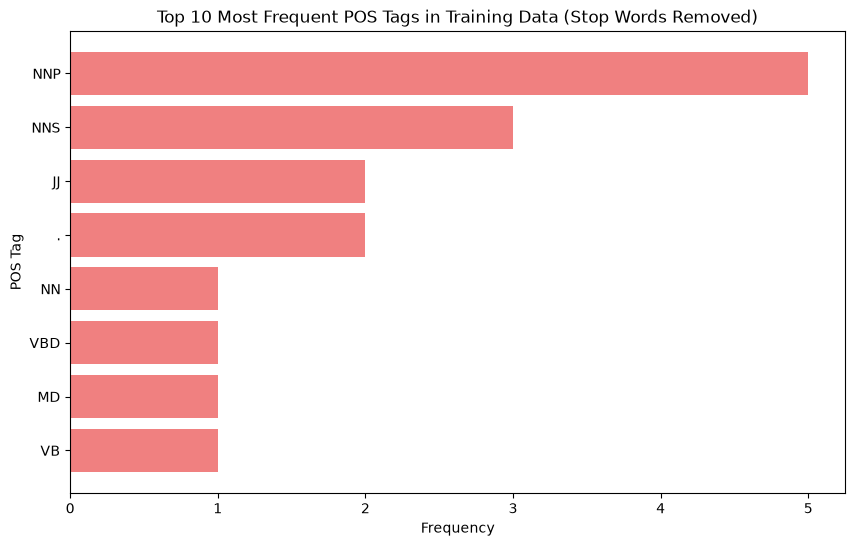

[('NNP', 5), ('NNS', 3), ('JJ', 2), ('.', 2), ('NN', 1), ('VBD', 1), ('MD', 1), ('VB', 1)]


In [44]:
if top_10_pos_tags:
    # Unzip the list of(tag, count)tuples in two separate lists
    tags, counts = zip(*top_10_pos_tags)
    # plt is assumed to be imported as matplotlib.pyplot:
    plt.figure(figsize=(10,6))
    # Create a horizontal bar chart;
    # convert tuples from zip to lists for plotting
    plt.barh(list(tags), list(counts), color='lightcoral')
    plt.xlabel('Frequency')
    plt.ylabel('POS Tag')
    plt.title(
        'Top 10 Most Frequent POS Tags in '
        'Training Data (Stop Words Removed)'
    )
    # Invert y-axis to show the most frequent item at the top
    plt.gca().invert_yaxis()
    plt.show()
else:
    # This message is displayed if X_train was empty,
    # all tokens were stop words,
    # or no tokens remained after filtering to be tagged.
    print(
        "No POS tags found to display. "
        "Check X_train data and stop word filtering process."
    )
print(top_10_pos_tags)

**Verification against the book:** Figure 9.3 is reproduced — NNP 5, NNS 3, JJ 2, `.` 2, NN 1, VBD 1, MD 1, VB 1 ✔. The title says "Top 10" but only **8** distinct tags exist in two sentences, and "proper nouns, nouns and adjectives make up the majority" is a statement about 17 tokens — a mechanical illustration, not a finding.

**Extension 1 — is it wise to remove stop words *before* tagging?** The tagger is a context-dependent model (it looks at neighbouring words); deleting words first changes the context. Compare the tags of the surviving tokens with and without the removal:

In [45]:
for text_content in X_train:
    tokens = nltk.word_tokenize(text_content)
    full = nltk.pos_tag(tokens)                                                  # tag the whole sentence
    kept_in_context = [(w, t) for w, t in full if w.lower() not in stop_words_set]
    filtered_first = nltk.pos_tag([w for w in tokens if w.lower() not in stop_words_set])
    diffs = [(a, b) for a, b in zip(kept_in_context, filtered_first) if a != b]
    print(f"{len(kept_in_context)} surviving tokens | tags that differ: {len(diffs)}", diffs)

8 surviving tokens | tags that differ: 0 []
8 surviving tokens | tags that differ: 0 []


In these two sentences the answer is **no difference**: all 8 surviving tokens of each sentence receive identical tags, so the book's order (filter, then tag) does no harm here. That is not guaranteed — the tagger's decision depends on the neighbouring words — so the safer routine is the one in the first line of the cell: tag the intact sentence, *then* drop the stop words.

**Extension 2 — a poor man's NER from the POS tags.** Consecutive proper-noun tags (`NNP`/`NNPS`) form a candidate named entity:

In [46]:
def proper_noun_chunks(tagged):
    chunks, current = [], []
    for token, tag in tagged:
        if tag in ("NNP", "NNPS"):
            current.append(token)
        elif current:
            chunks.append(" ".join(current)); current = []
    if current:
        chunks.append(" ".join(current))
    return chunks

for text_content in X_train + X_test:
    print(proper_noun_chunks(nltk.pos_tag(nltk.word_tokenize(text_content))), "<-", text_content[:60] + "...")

['Northern'] <- Northern liberals are the chief supporters of civil rights a...
['Dan Morgan', 'Ann Turner'] <- Dan Morgan told himself he would forget Ann Turner ....
[] <- He was well rid of her ....
[] <- They have also led the nation in the direction of a welfare ...


`Dan Morgan` and `Ann Turner` are found, but `Northern` (a sentence-initial adjective the tagger mistook for a proper noun) is a false positive, and the chunker cannot say *what kind* of entity it found (person? place? organisation?) nor find lower-case or non-NNP entities. A real NER model returns typed spans such as `PERSON: Dan Morgan`.

**Extension 3 — what n-grams capture in a real corpus.** Most frequent *bigrams* (stop words removed, in ≥ 5 reviews) over the 2,000 movie reviews, and the number of features for different `ngram_range` values:

In [47]:
from sklearn.feature_extraction.text import CountVectorizer

reviews = [movie_reviews.raw(f) for f in movie_reviews.fileids()]
review_labels = [movie_reviews.categories(f)[0] for f in movie_reviews.fileids()]

bi = CountVectorizer(ngram_range=(2, 2), stop_words='english', min_df=5)
B = bi.fit_transform(reviews)
bc = np.asarray(B.sum(axis=0)).ravel()
print("most frequent bigrams:", [(bi.get_feature_names_out()[i], int(bc[i])) for i in np.argsort(bc)[::-1][:12]])

sizes = {}
for rng in [(1, 1), (1, 2), (1, 3)]:
    sizes[f"ngram_range={rng}"] = len(CountVectorizer(ngram_range=rng).fit(reviews).vocabulary_)
display(pd.Series(sizes, name="features (2,000 reviews)").to_frame())

most frequent bigrams: [('special effects', 387), ('ve seen', 279), ('new york', 249), ('year old', 193), ('high school', 188), ('star wars', 166), ('looks like', 145), ('science fiction', 144), ('sci fi', 144), ('don know', 133), ('takes place', 123), ('real life', 122)]


,"features (2,000 reviews)"
"ngram_range=(1, 1)",39659
"ngram_range=(1, 2)",538909
"ngram_range=(1, 3)",1529707


The most frequent bigrams are real multi-word concepts — `special effects` (387), `new york`, `high school`, `star wars`, `science fiction` — that a unigram model splits apart. They also expose the limits of the default tokeniser: `ve seen` and `don know` come from *I've seen* and *don't know* (the token pattern splits at the apostrophe and drops the one-letter `t`), and `sci fi` and `science fiction` are two features for one idea.
The vocabulary explodes with *n*: 39,659 unigrams → 538,909 (1–2-grams) → 1,529,707 (1–3-grams), from only 2,000 documents.

Do the extra features help a classifier? 5-fold cross-validated accuracy of TF-IDF + logistic regression with the n-gram range as the only change:

In [48]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

rev_arr = np.array(reviews, dtype=object)
cv5 = StratifiedKFold(5, shuffle=True, random_state=2024)
rows = {}
for name, vec in {"unigrams":                      TfidfVectorizer(),
                  "uni+bigrams":                   TfidfVectorizer(ngram_range=(1, 2)),
                  "uni+bigrams, min_df=2":         TfidfVectorizer(ngram_range=(1, 2), min_df=2),
                  "uni+bi+trigrams, min_df=2":     TfidfVectorizer(ngram_range=(1, 3), min_df=2)}.items():
    s = cross_val_score(make_pipeline(vec, LogisticRegression(max_iter=1000)), rev_arr, review_labels, cv=cv5)
    rows[name] = {"mean CV accuracy": s.mean(), "std over folds": s.std()}
display(pd.DataFrame(rows).T.round(3))

,mean CV accuracy,std over folds
unigrams,0.824,0.013
uni+bigrams,0.800,0.017
"uni+bigrams, min_df=2",0.817,0.014
"uni+bi+trigrams, min_df=2",0.812,0.012


More features did **not** help here: unigrams 0.824, all uni+bigrams 0.800 (539k features), with `min_df=2` 0.817, with trigrams 0.812. The differences (at most 2.4 points; fold-to-fold std 0.012–0.017, standard error of a mean ≈ 0.009) are small and nominally *negative*: with 1,600 training reviews per fold and the default L2 penalty, mostly one-off n-grams add noise faster than signal.
n-grams tend to pay off with more data, tuned regularisation (`C`, `min_df`) or tasks in which phrases matter more than they do for this sentiment corpus — an empirical question, not a given.

### There's more…
Dependency parsing (the grammatical tree of a sentence) and sentiment analysis add yet more structure; they need libraries beyond scikit-learn (spaCy, NLTK's VADER, transformers).

### Theory — richer text features
* **n-gram:** a window of *n* tokens. `ngram_range=(1,2)` = unigrams + bigrams. The vocabulary explodes (Extension 3): most n-grams occur once, so use `min_df` / `max_features` and strong regularisation.
* **Character n-grams** (`analyzer='char_wb'`) are robust to typos and morphology and work for languages without clear word boundaries.
* **POS / NER features** are *added* columns (counts of nouns, entities per document, …) or used as filters (keep only nouns and adjectives). They need a tagger trained on a language — and tagging is context-dependent, so tag the intact sentence.
* **More features ≠ better model:** each added feature type must earn its place in cross-validation.

### Hands-on workflow (book)
Choose a dataset, clean it, extract n-grams with several ranges, add POS tags and NER with spaCy, train classifiers on the features, evaluate with accuracy/precision/recall/F1 and plot the n-gram frequencies or entity distributions. **Exercise 2** covers the n-gram part.

## 4. Implementing text classification models

**Summary.** With text turned into a TF-IDF matrix, any classifier can be used. The book compares three standard choices for categorising documents: **Multinomial Naive Bayes**, a **support vector machine** and **logistic regression**.

### Getting ready — the whole Brown corpus
500 documents, labelled with their genre (the first of its categories). The book's imports include a repeated `classification_report`.

In [49]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import nltk
from nltk.corpus import brown
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

In [50]:
# It's good practice to include this, though in a real notebook,
# it might be run once in a separate cell.
try:
    nltk.data.find('corpora/brown.zip')
except nltk.downloader.DownloadError:
    nltk.download('brown', quiet=True)
try:
    # Punkt is a tokenizer dependency
    # for some NLTK corpus operations.
    nltk.data.find('tokenizers/punkt')
except nltk.downloader.DownloadError:
    nltk.download('punkt', quiet=True)

print("does nltk.downloader.DownloadError exist in this NLTK version?", hasattr(nltk.downloader, "DownloadError"))

does nltk.downloader.DownloadError exist in this NLTK version? False


> **Book correction (NLTK API).** The book guards the downloads with `except nltk.downloader.DownloadError`. In NLTK 3.10.3 that exception class **does not exist** (printed above), and `nltk.data.find` raises **`LookupError`** when a resource is missing. On a machine without the corpus, Python would first raise `LookupError` and then fail with `AttributeError` while trying to evaluate the `except` clause — the cell only runs because the data was already downloaded by the setup cell. The robust pattern is `except LookupError:` (as in the book's other recipes). Also, `'tokenizers/punkt'` is the legacy pickle tokenizer; current NLTK uses `punkt_tab`.

In [51]:
document_ids = brown.fileids()
texts = [
    ' '.join(brown.words(file_id))
    for file_id in document_ids
]
# Each document in Brown corpus is assigned to a category
# (genre).
# We use the first category as the label.
raw_labels = [
    brown.categories(file_id)[0]
    for file_id in document_ids
]

In [52]:
unique_raw_labels = sorted(list(set(raw_labels)))
label_to_int_mapping = {
    label: i
    for i, label in enumerate(unique_raw_labels)
}
labels = [
    label_to_int_mapping[label]
    for label in raw_labels
]

In [53]:
# The Brown corpus has 500 documents and 15 categories.
# The minimum number of samples per category is >20,
# so stratify will work fine.
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.5,
    stratify=labels, random_state=2024
)

counts_ = pd.Series(raw_labels).value_counts()
print("documents:", len(texts), "| genres:", len(unique_raw_labels), "| train / test:", len(X_train), "/", len(X_test))
print("documents per genre:", counts_.to_dict())

documents: 500 | genres: 15 | train / test: 250 / 250
documents per genre: {'learned': 80, 'belles_lettres': 75, 'lore': 48, 'news': 44, 'hobbies': 36, 'government': 30, 'fiction': 29, 'adventure': 29, 'romance': 29, 'editorial': 27, 'mystery': 24, 'reviews': 17, 'religion': 17, 'humor': 9, 'science_fiction': 6}


> **Book correction (a false comment).** The comment says "the minimum number of samples per category is > 20". The smallest genres are `science_fiction` (**6** documents), `humor` (9), `reviews` and `religion` (17 each). Stratification still works (it only needs ≥ 2 per class), but with 3 test documents of `science_fiction` any per-class score for that genre is close to meaningless. The genres are also very unbalanced (80 `learned` vs 6 `science_fiction`).

### How to do it…
Vectorise with TF-IDF, then train the three models.

In [54]:
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)
print("TF-IDF matrix:", X_train_vect.shape)

TF-IDF matrix: (250, 30682)


In [55]:
nb_clf = MultinomialNB()
nb_clf.fit(X_train_vect, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](15,)","[14.,38.,13.,..., 9.,14., 3.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](15,)","[-2.88,-1.88,-2.96,...,-3.32,-2.88,-4.42]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](15,)","[ 0, 1, 2,...,12,13,14]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](15, 30682)","[[0.01,0. ,0. ,...,0. ,0. ,0. ], [0.02,0.1 ,0. ,...,0. ,0. ,0. ], [0. ,0.22,0. ,...,0. ,0. ,0. ], ..., [0. ,0.03,0. ,...,0. ,0. ,0. ], [0. ,0. ,0. ,...,0. ,0. ,0. ], [0. ,0. ,0. ,...,0. ,0. ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](15, 30682)","[[-10.32,-10.34,-10.34,...,-10.34,-10.34,-10.34], [-10.34,-10.26,-10.35,...,-10.35,-10.35,-10.35], [-10.34,-10.14,-10.34,...,-10.34,-10.34,-10.34], ..., [-10.34,-10.31,-10.34,...,-10.34,-10.34,-10.34], [-10.34,-10.34,-10.34,...,-10.34,-10.34,-10.34], [-10.33,-10.33,-10.33,...,-10.33,-10.33,-10.33]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30682


In [56]:
svm_clf = SVC(random_state=2024)
svm_clf.fit(X_train_vect, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",2024
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [57]:
lr_clf = LogisticRegression(random_state=2024, max_iter=1000)
lr_clf.fit(X_train_vect, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",2024
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Evaluate the three models (the book prints a styled classification report for each):

In [58]:
models = {
    'Naive Bayes': nb_clf, 'SVM': svm_clf,
    'Logistic Regression': lr_clf
}
for name, model in models.items():
    y_pred = model.predict(X_test_vect)
    print(f'{name} Classification Report:')
    # Generate classification report as a dictionary
    # Utilize unique_raw_labels for
    # target_names to show actual class names
    report_dict = classification_report(
        y_test, y_pred,
        target_names=unique_raw_labels,
        output_dict=True, zero_division=0
    )
    # Convert to DataFrame
    report_df = pd.DataFrame(report_dict).transpose()
    # Stylize the DataFrame
    styled_df = (report_df
        .style
        .background_gradient(
            cmap='Blues',
            subset=['precision', 'recall', 'f1-score']
        )
        .format({
            'precision': '{:.3f}',
            'recall': '{:.3f}',
            'f1-score': '{:.3f}',
            'support': '{:.0f}'
        })
    )
    display(styled_df)
    print("\n")

Naive Bayes Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,15
belles_lettres,0.173,1.000,0.295,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.556,0.500,0.526,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12


SVM Classification Report:


,precision,recall,f1-score,support
adventure,0.400,0.133,0.200,15
belles_lettres,0.236,0.946,0.378,37
editorial,0.000,0.000,0.000,14
fiction,0.312,0.357,0.333,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.424,0.700,0.528,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12




Logistic Regression Classification Report:


,precision,recall,f1-score,support
adventure,1.000,0.067,0.125,15
belles_lettres,0.231,0.919,0.370,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,1.000,0.056,0.105,18
humor,0.000,0.000,0.000,4
learned,0.377,0.725,0.496,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12


**Verification against the book:** the three tables are the book's Figures 9.4–9.6 to the third decimal — e.g. Naive Bayes: `belles_lettres` precision 0.173 / recall 1.000 / F1 0.295, `learned` 0.556 / 0.500 / 0.526, overall accuracy **0.228**; SVM: accuracy **0.332** (`news` precision 1.000, recall 0.409); logistic regression: accuracy **0.324** (`romance` F1 0.621, `adventure` and `hobbies` precision 1.000 with recall < 0.07) ✔.
(The `support` shown on the *accuracy* row is the accuracy value rounded by the `'{:.0f}'` format, i.e. `0`; the true support is 250.)

The book's accuracy bar chart:

In [59]:
model_accuracies = {}
for model_name, model_instance in models.items():
    y_pred = model_instance.predict(X_test_vect)
    # Using parameters consistent with the
    # report generation in the preceding cells.
    # Assumes unique_raw_labels is defined
    # and available from a previous cell,
    # as it was used in file_context_0
    # for generating classification reports.
    # The target_names parameter does not affect the
    # overall 'accuracy' value but is included
    # for consistency.
    report_dict = classification_report(
        y_test, y_pred,
        target_names=unique_raw_labels,
        output_dict=True, zero_division=0
    )
    model_accuracies[model_name] = report_dict['accuracy']
plt.figure(figsize=(8,6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

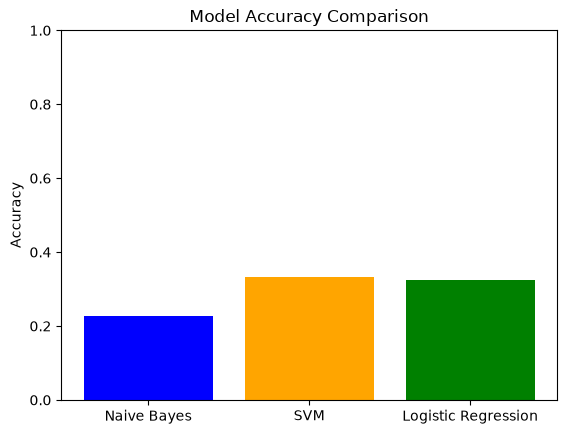

{'Naive Bayes': 0.228, 'SVM': 0.332, 'Logistic Regression': 0.324}


In [60]:
# .keys() and .values() from the same dictionary will be in
# corresponding orders.
plt.bar(
    model_accuracies.keys(),
    model_accuracies.values(),
    color=['blue', 'orange', 'green']
)
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
plt.show()
print({k: round(v, 3) for k, v in model_accuracies.items()})

**Verification against the book:** Figure 9.7 — Naive Bayes 0.228, SVM 0.332, logistic regression 0.324 ✔.

### How it works… — and what the book's interpretation gets wrong
The book says Naive Bayes "performs well on text data", SVM "excels at capturing complex relationships" and logistic regression gives "robust predictions … useful for binary classification tasks". Its own results contradict the first claim: Naive Bayes is the **worst** model (0.228) and, as the next cell shows, it only ever predicts **two** of the 15 genres.
A single number needs a baseline and a diagnosis. First the baseline, and how many classes each model actually uses:

In [61]:
y_test_arr = np.array(y_test)
majority_share = np.mean(y_test_arr == np.bincount(y_train).argmax())
print(f"majority-class baseline (always predict 'learned'): accuracy {majority_share:.3f}\n")

rows = {}
for name, model in models.items():
    p = model.predict(X_test_vect)
    rows[name] = {"accuracy": (p == y_test_arr).mean(), "distinct classes predicted (of 15)": len(set(p))}
display(pd.DataFrame(rows).T.round(3))

majority-class baseline (always predict 'learned'): accuracy 0.160



,accuracy,distinct classes predicted (of 15)
Naive Bayes,0.228,2.0
SVM,0.332,6.0
Logistic Regression,0.324,7.0


All three are only 7–17 points above the 0.16 baseline and use 2 / 6 / 7 of the 15 classes: they are **under-fitted**, not "highly differentiated". The cause is the combination *default hyper-parameters × TF-IDF features*. A TF-IDF row is L2-normalised over ~30,000 columns, so each entry is tiny (~0.01):
* `MultinomialNB(alpha=1.0)` adds 1 to every feature count; next to TF-IDF values of 0.01 the smoothing term swamps the data and the class prior (the large classes) wins;
* `LogisticRegression(C=1.0)` and `SVC(C=1.0)` regularise strongly relative to such small feature values.

Sweeping the one parameter that matters for each model on the same held-out half (a fair sweep would use cross-validation; the 5-fold version is below):

In [62]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC

rows = []
for a in [1, 0.1, 0.01, 0.001]:
    p = MultinomialNB(alpha=a).fit(X_train_vect, y_train).predict(X_test_vect)
    rows.append({"model": "MultinomialNB on TF-IDF", "setting": f"alpha={a}", "accuracy": (p == y_test_arr).mean(), "classes used": len(set(p))})
cnt = CountVectorizer(); Ac = cnt.fit_transform(X_train); Bc = cnt.transform(X_test)
for a in [1, 0.1, 0.01]:
    p = MultinomialNB(alpha=a).fit(Ac, y_train).predict(Bc)
    rows.append({"model": "MultinomialNB on raw counts", "setting": f"alpha={a}", "accuracy": (p == y_test_arr).mean(), "classes used": len(set(p))})
for C in [1, 10, 100, 1000]:
    p = LogisticRegression(C=C, max_iter=2000).fit(X_train_vect, y_train).predict(X_test_vect)
    rows.append({"model": "LogisticRegression", "setting": f"C={C}", "accuracy": (p == y_test_arr).mean(), "classes used": len(set(p))})
for C in [1, 10]:
    p = LinearSVC(C=C).fit(X_train_vect, y_train).predict(X_test_vect)
    rows.append({"model": "LinearSVC", "setting": f"C={C}", "accuracy": (p == y_test_arr).mean(), "classes used": len(set(p))})
for C in [1, 10, 100]:
    p = SVC(kernel="linear", C=C).fit(X_train_vect, y_train).predict(X_test_vect)
    rows.append({"model": "SVC(kernel='linear')", "setting": f"C={C}", "accuracy": (p == y_test_arr).mean(), "classes used": len(set(p))})
display(pd.DataFrame(rows).round(3).set_index(["model", "setting"]))

accuracy  classes used
model                       setting                            
MultinomialNB on TF-IDF     alpha=1         0.228             2
                            alpha=0.1       0.272             3
                            alpha=0.01      0.468            11
                            alpha=0.001     0.504            12
MultinomialNB on raw counts alpha=1         0.424            10
                            alpha=0.1       0.512            12
                            alpha=0.01      0.496            12
LogisticRegression          C=1             0.324             7
                            C=10            0.440            12
                            C=100           0.496            13
                            C=1000          0.492            13
LinearSVC                   C=1             0.480            13
                            C=10            0.476            14
SVC(kernel='linear')        C=1             0.348             7
                            C=10            0.480            13
                            C=100           0.480            13

Reading the table: every model roughly doubles (0.23–0.33 → 0.47–0.51) once the smoothing or regularisation matches the feature scale, and the number of genres it actually predicts rises from 2–7 to 11–14.
* **Naive Bayes on TF-IDF** needs `alpha` 100–1000× smaller than the default (0.228 → 0.504). On raw counts (larger values) the default already gives 0.424 and `alpha=0.1` gives 0.512.
* **Logistic regression** goes from 0.324 (`C=1`) to 0.496 (`C=100`).
* **A linear SVM** reaches 0.48 at `C=1` (`LinearSVC`) — the book's RBF `SVC` needs the same kind of fix (`kernel="linear"`, `C=10` → 0.48).

After tuning, the three models are within a few points of each other (≈ 0.5). The ranking in the book's Figure 9.7 (SVM ≈ LR > NB) mostly ranks *how badly each default is mis-scaled for this data*, not the models.

The same conclusion with 5-fold cross-validation on all 500 documents (vectoriser inside the pipeline; the book's default settings vs sensible ones):

In [63]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

texts_arr = np.array(texts, dtype=object)
labels_arr = np.array(labels)
cv5 = StratifiedKFold(5, shuffle=True, random_state=2024)
rows = {}
for name, est in {
    "Naive Bayes (default alpha=1)": make_pipeline(TfidfVectorizer(), MultinomialNB()),
    "Naive Bayes (alpha=0.01)":      make_pipeline(TfidfVectorizer(), MultinomialNB(alpha=0.01)),
    "Logistic regression (C=1)":     make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000)),
    "Logistic regression (C=100)":   make_pipeline(TfidfVectorizer(), LogisticRegression(C=100, max_iter=2000)),
    "LinearSVC (C=1)":               make_pipeline(TfidfVectorizer(), LinearSVC()),
}.items():
    s = cross_val_score(est, texts_arr, labels_arr, cv=cv5)
    rows[name] = {"mean CV accuracy": s.mean(), "std over folds": s.std()}
display(pd.DataFrame(rows).T.round(3))

,mean CV accuracy,std over folds
Naive Bayes (default alpha=1),0.244,0.023
Naive Bayes (alpha=0.01),0.480,0.017
Logistic regression (C=1),0.374,0.030
Logistic regression (C=100),0.518,0.034
LinearSVC (C=1),0.510,0.022


The same picture on all 500 documents: Naive Bayes 0.244 → 0.480 (`alpha=0.01`), logistic regression 0.374 → 0.518 (`C=100`), `LinearSVC` 0.510 out of the box (fold-to-fold std 0.017–0.034, so the three tuned models are statistically indistinguishable). The book's headline accuracies (0.23–0.33) are therefore a statement about *default hyper-parameters*, not about what these models can do on this corpus.

**Extension — why is ~0.5 the ceiling here?** The genres are overlapping *registers* (`belles_lettres`, `learned`, `lore`, `hobbies`, `government` are all non-fiction prose), 250 training documents for 15 classes is little, and several classes have fewer than 20 documents. The confusion matrix of the tuned logistic regression shows where the errors go:

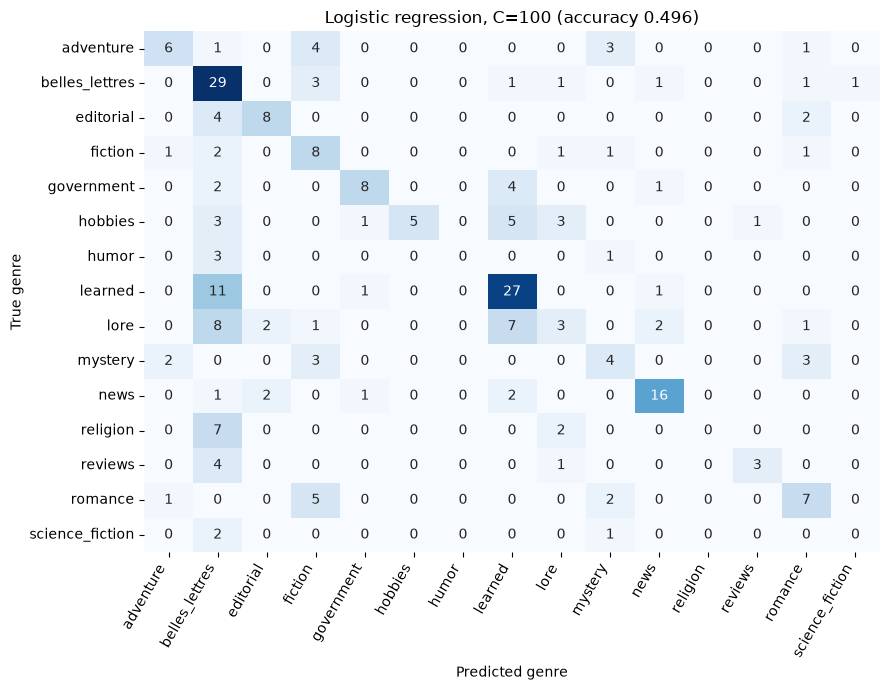

largest confusions (count, true -> predicted): [(np.int64(11), 'learned', 'belles_lettres'), (np.int64(8), 'lore', 'belles_lettres'), (np.int64(7), 'religion', 'belles_lettres'), (np.int64(7), 'lore', 'learned'), (np.int64(5), 'romance', 'fiction'), (np.int64(5), 'hobbies', 'learned')]


In [64]:
from sklearn.metrics import confusion_matrix

lr100 = LogisticRegression(C=100, max_iter=2000).fit(X_train_vect, y_train)
p100 = lr100.predict(X_test_vect)
cm = confusion_matrix(y_test_arr, p100)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=unique_raw_labels, yticklabels=unique_raw_labels, cbar=False)
plt.xlabel('Predicted genre'); plt.ylabel('True genre'); plt.title(f'Logistic regression, C=100 (accuracy {np.mean(p100 == y_test_arr):.3f})')
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()

off = [(cm[i, j], unique_raw_labels[i], unique_raw_labels[j]) for i in range(15) for j in range(15) if i != j]
print("largest confusions (count, true -> predicted):", sorted(off, reverse=True)[:6])

`belles_lettres` acts as a **sink**: the largest column of the matrix, receiving `learned` (11 documents), `lore` (8), `religion` (7), `editorial` and `reviews` (4 each), `humor` (3), … The only intuitive confusion between close neighbours is `romance` → `fiction` (5). These genres are overlapping registers of prose, and 250 training documents for 15 classes (several with fewer than 20) leave little to separate them — so ≈ 0.5 here reflects overlapping labels and little data at least as much as the choice of algorithm.

**Extension — logistic regression is interpretable.** The book praises it for interpretability; here are the highest-weight words of the tuned model for four genres (for linear models on TF-IDF each class has one weight per word):

In [65]:
terms = vectorizer.get_feature_names_out()
for genre in ["news", "religion", "romance", "hobbies"]:
    k = label_to_int_mapping[genre]
    top = np.argsort(lr100.coef_[k])[::-1][:10]
    print(f"{genre:9s}:", ", ".join(terms[top]))

news     : mrs, libraries, library, said, mantle, week, 000, the, year, monday
religion : god, we, zen, lo, slavery, shu, christ, atom, peas, chinese
romance  : you, spencer, her, phil, and, cady, she, maggie, henrietta, richard
hobbies  : prokofieff, your, hanover, juniors, site, engineer, vernon, shooting, you, boat


Some weights are meaningful — `god`, `christ` (religion); `you`, `her`, `she` (romance); `said`, `week`, `monday`, `mrs` (news) — but many are **memorised content of single documents**: the character names `spencer`, `cady`, `maggie`, `henrietta` (romance), `prokofieff`, `hanover`, `juniors` (hobbies), `mantle`, `libraries` (news), `atom`, `peas`, `zen` (religion). With 6–36 documents per genre and weak regularisation (`C=100`) the model leans on such words, which will not recur in new documents — a sign of overfitting that the ≈ 0.5 held-out accuracy reflects. Linear models *are* interpretable, but the weights need a sanity check rather than trust.

### Theory — the three text classifiers
* **Multinomial Naive Bayes** applies Bayes' rule with the "naive" assumption that words are independent given the class: $P(c\mid d)\propto P(c)\prod_t P(t\mid c)^{x_t}$. It is a *generative* model, trains in one pass over the counts (very fast, good with little data) and `alpha` is Laplace/Lidstone smoothing, which must be matched to the scale of the features (counts vs TF-IDF).
* **Support vector machine** — a maximum-margin classifier (Chapter 7). On sparse high-dimensional text, a **linear** kernel (`LinearSVC`) is the standard choice; the default RBF `SVC` is usually not (it predicted only 6 genres here).
* **Logistic regression** — a discriminative linear model (Chapter 6) giving class probabilities and per-word weights; `C` controls regularisation.
* **Why linear models suit text:** with 30,000 features and 250 documents the classes are almost always linearly separable, so extra non-linearity mostly adds variance; regularisation strength is the key hyper-parameter.
* **Other options the book mentions:** ensembles, deep learning and embeddings, and hyper-parameter tuning — which, as shown above, would have changed this chapter's conclusions.

### Hands-on workflow (book)
Pick a text-classification dataset, clean it, vectorise with TF-IDF, train Naive Bayes, SVM and logistic regression, evaluate them with accuracy/precision/recall/F1 and visualise the results — as above.

## 5. Multiclass classification strategies

**Summary.** In **multiclass** classification each document belongs to exactly one of more than two classes (Chapter 6). Binary classifiers such as logistic regression can be extended with two meta-strategies:
* **One-vs-Rest (OvR):** one classifier per class, "this class against all the others"; the class with the highest score wins.
* **One-vs-One (OvO):** one classifier per *pair* of classes; the class that wins most pairwise votes is predicted.

(The book's introduction repeats a sentence about "multiple labels or multiple labels per inference". That describes **multilabel** classification — a document with *several* labels at once — which is a different problem from multiclass; it is demonstrated at the end of this section.)

### Getting ready
The book uses the Brown corpus again — this time with `brown.raw`.

In [66]:
import nltk
from nltk.corpus import brown
from sklearn.model_selection import train_test_split          # missing from the book's imports
from sklearn.feature_extraction.text import TfidfVectorizer   # (they are imported in earlier recipes)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import pandas as pd

In [67]:
# Using quiet=True to suppress verbose download output in the
# notebook
try:
    # Check if already downloaded and accessible
    _ = brown.fileids()
except LookupError:
    nltk.download('brown', quiet=True)
except Exception:
    # Catch other potential NLTK setup issues
    nltk.download('brown', quiet=True)

In [68]:
file_ids = brown.fileids()
texts = [brown.raw(file_id) for file_id in file_ids]
# Use the filename (without .txt extension) as the label
labels = [brown.categories(file_id)[0] for file_id in file_ids]

In [69]:
# With 6 documents in brown,
# test_size=0.5 gives 3 train and 3 test samples.
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.5, random_state=2024)

print("documents:", len(texts), "| train / test:", len(X_train), "/", len(X_test))
print("\n--- the first 160 characters of brown.raw('ca01') ---")
print(repr(texts[0][:160]))

documents: 500 | train / test: 250 / 250

--- the first 160 characters of brown.raw('ca01') ---
"\n\n\tThe/at Fulton/np-tl County/nn-tl Grand/jj-tl Jury/nn-tl said/vbd Friday/nr an/at investigation/nn of/in Atlanta's/np$ recent/jj primary/nn election/nn produc"


> **Book correction (comments and data).** Three statements in this recipe are wrong:
> 1. *"With 6 documents in brown, `test_size=0.5` gives 3 train and 3 test samples"* — Brown has **500** documents; the split gives 250 / 250.
> 2. *"Use the filename (without .txt extension) as the label"* — the label is the **genre** (`brown.categories`).
> 3. The introduction quotes NLTK as saying the corpus "includes content from a Firefox discussion forum, conversations overheard in New York, the movie script of Pirates of the Caribbean, personal advertisements, and wine reviews". That is the description of NLTK's **`webtext`** corpus, not Brown (1960s American prose in 15 genres).
>
> Also note what `brown.raw` returns: **tagged text** (`The/at Fulton/np-tl County/nn-tl …`). `TfidfVectorizer` splits `The/at` into the tokens `the` and `at`, so the POS-tag fragments (`at`, `nn`, `jj`, `np`, `tl`, …) become features too. Recipe 4 used `' '.join(brown.words(...))` — plain words — so the two recipes do not use the same features.

### How to do it…

In [70]:
from sklearn.multiclass import (
    OneVsOneClassifier, OneVsRestClassifier)
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

In [71]:
ovr_clf = OneVsRestClassifier(LogisticRegression(
    random_state=2024, solver='liblinear'))
ovr_clf.fit(X_train_vect, y_train)
y_pred_ovr = ovr_clf.predict(X_test_vect)

In [72]:
ovo_clf = OneVsOneClassifier(LogisticRegression(
    random_state=2024, solver='liblinear'))
ovo_clf.fit(X_train_vect, y_train)
y_pred_ovo = ovo_clf.predict(X_test_vect)

In [73]:
# Added zero_division=0 to handle cases where
# precision/recall might be ill-defined
# due to no predicted samples or no true samples for a class.
print('One-vs-Rest Classification Report:')
report_ovr_dict = classification_report(
    y_test, y_pred_ovr,
    zero_division=0, output_dict=True
)
report_ovr_df = pd.DataFrame(
    report_ovr_dict
).transpose()
styled_ovr_df = (report_ovr_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ovr_df)
print("\n")
print('One-vs-One Classification Report:')
report_ovo_dict = classification_report(
    y_test, y_pred_ovo,
    zero_division=0, output_dict=True
)
report_ovo_df = pd.DataFrame(
    report_ovo_dict
).transpose()
styled_ovo_df = (report_ovo_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ovo_df)
print("\n")

One-vs-Rest Classification Report:


,precision,recall,f1-score,support
adventure,0.400,0.143,0.211,14
belles_lettres,0.206,0.568,0.302,37
editorial,0.000,0.000,0.000,9
fiction,0.000,0.000,0.000,13
government,0.000,0.000,0.000,19
hobbies,0.000,0.000,0.000,21
humor,0.000,0.000,0.000,6
learned,0.282,0.861,0.425,36
lore,0.000,0.000,0.000,29
mystery,0.000,0.000,0.000,12




One-vs-One Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,14
belles_lettres,0.200,0.703,0.311,37
editorial,0.000,0.000,0.000,9
fiction,0.000,0.000,0.000,13
government,0.000,0.000,0.000,19
hobbies,0.000,0.000,0.000,21
humor,0.000,0.000,0.000,6
learned,0.292,0.861,0.437,36
lore,0.000,0.000,0.000,29
mystery,0.000,0.000,0.000,12


In [74]:
print("printed split (test_size=0.5, no stratify): test documents", len(y_test),
      "| OvR accuracy:", round(np.mean(np.array(y_pred_ovr) == np.array(y_test)), 3),
      "| OvO accuracy:", round(np.mean(np.array(y_pred_ovo) == np.array(y_test)), 3))

printed split (test_size=0.5, no stratify): test documents 250 | OvR accuracy: 0.272 | OvO accuracy: 0.264


> **Book correction (the printed code does not produce the book's figures).** Figures 9.8 and 9.9 have **150** test documents (support 9, 22, 8, 9, 9, 11, 3, 24, 14, 7, 13, 5, 5, 9, 2) and accuracies **0.307** (OvR) and **0.273** (OvO). The code as printed (`test_size=0.5`, no `stratify`) gives 250 test documents with different supports and accuracies **0.272 / 0.264** (above).
> The figures are reproduced exactly with `test_size=0.3, stratify=labels, random_state=2024` (still `brown.raw` text); the next cell reruns the book's evaluation code on that split and checks the support column against the book.

In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.3, stratify=labels, random_state=2024)
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

ovr_clf = OneVsRestClassifier(LogisticRegression(random_state=2024, solver='liblinear')).fit(X_train_vect, y_train)
ovo_clf = OneVsOneClassifier(LogisticRegression(random_state=2024, solver='liblinear')).fit(X_train_vect, y_train)
y_pred_ovr, y_pred_ovo = ovr_clf.predict(X_test_vect), ovo_clf.predict(X_test_vect)

def styled_report(y_true, y_pred):
    df = pd.DataFrame(classification_report(y_true, y_pred, zero_division=0, output_dict=True)).transpose()
    return (df.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
              .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

book_support = [9, 22, 8, 9, 9, 11, 3, 24, 14, 7, 13, 5, 5, 9, 2]
rep = classification_report(y_test, y_pred_ovr, zero_division=0, output_dict=True)
support = [int(rep[c]["support"]) for c in sorted(set(labels))]
print("support column equals the book's Figures 9.8/9.9:", support == book_support, "| test documents:", len(y_test))
print("OvR accuracy:", round(np.mean(np.array(y_pred_ovr) == np.array(y_test)), 3), "| OvO accuracy:", round(np.mean(np.array(y_pred_ovo) == np.array(y_test)), 3))
print('\nOne-vs-Rest Classification Report:');  display(styled_report(y_test, y_pred_ovr))
print('One-vs-One Classification Report:');    display(styled_report(y_test, y_pred_ovo))

support column equals the book's Figures 9.8/9.9: True | test documents: 150
OvR accuracy: 0.307 | OvO accuracy: 0.273

One-vs-Rest Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.224,0.773,0.347,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.345,0.792,0.481,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7


One-vs-One Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.185,0.773,0.298,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.373,0.792,0.507,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7


**Verification against the book:** Figure 9.8 (OvR): accuracy **0.307**, `belles_lettres` 0.224 / 0.773 / 0.347, `learned` 0.345 / 0.792 / 0.481, `news` 0.875 / 0.538 / 0.667, `romance` 0.300 / 0.333 / 0.316. Figure 9.9 (OvO): accuracy **0.273**, `belles_lettres` 0.185 / 0.773 / 0.298, `learned` 0.373 / 0.792 / 0.507, `news` 0.833 / 0.385 / 0.526, `romance` 0 ✔ — all reproduced.

> **Book correction (the two models are swapped in the commentary).** "The term *romance* did not elicit any predictive performance compared to OvO." In the figures it is the reverse: **OvR** scores F1 0.316 on `romance`, **OvO** scores 0.000 (it never predicts it).

### How it works…
The book recaps OvR (one classifier per class; efficient) and OvO (one per pair; "a higher number of models, but often providing better performance on balanced datasets"). The number of models is easy to check:

In [76]:
k = len(ovr_clf.classes_)
print(f"classes: {k} | OvR models: {len(ovr_clf.estimators_)} (= k) | OvO models: {len(ovo_clf.estimators_)} (= k(k-1)/2 = {k*(k-1)//2})")

import itertools
cls_counts = pd.Series(y_train).value_counts()
pair_sizes = [cls_counts[a] + cls_counts[b] for a, b in itertools.combinations(cls_counts.index, 2)]
print(f"training documents seen by each OvR model: all {len(y_train)} | by each OvO model: min {min(pair_sizes)}, median {int(np.median(pair_sizes))}, max {max(pair_sizes)}")

classes: 15 | OvR models: 15 (= k) | OvO models: 105 (= k(k-1)/2 = 105)
training documents seen by each OvR model: all 350 | by each OvO model: min 10, median 41, max 109


Each OvO model sees only the documents of its two classes — between **10** and **109** (median 41) instead of all 350 — and the weakest models are those that pair the tiny classes (`humor`, `science_fiction`).

**Is "OvR slightly edges out OvO" a robust result?** One split of 150 documents cannot tell (the standard error of an accuracy near 0.3 is ≈ 0.04). Repeat the stratified 70/30 split with 10 different seeds, with the book's default `C=1` and with `C=100`; and add scikit-learn's native multinomial logistic regression for reference:

In [77]:
res = {"OvR (C=1)": [], "OvO (C=1)": [], "OvR (C=100)": [], "OvO (C=100)": [], "multinomial LR (C=1)": []}
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(texts, labels, test_size=0.3, stratify=labels, random_state=seed)
    v = TfidfVectorizer(); A = v.fit_transform(Xtr); B = v.transform(Xte)
    for C in (1, 100):
        res[f"OvR (C={C})"].append(OneVsRestClassifier(LogisticRegression(C=C, solver='liblinear')).fit(A, ytr).score(B, yte))
        res[f"OvO (C={C})"].append(OneVsOneClassifier(LogisticRegression(C=C, solver='liblinear')).fit(A, ytr).score(B, yte))
    res["multinomial LR (C=1)"].append(LogisticRegression(max_iter=1000).fit(A, ytr).score(B, yte))
summary = pd.DataFrame({k: {"mean accuracy": np.mean(v), "std over splits": np.std(v)} for k, v in res.items()}).T
display(summary.round(3))
print("OvR beats OvO in", sum(a > b for a, b in zip(res["OvR (C=1)"], res["OvO (C=1)"])), "of 10 splits with C=1;",
      sum(a > b for a, b in zip(res["OvR (C=100)"], res["OvO (C=100)"])), "of 10 with C=100 (ties:", sum(a == b for a, b in zip(res["OvR (C=100)"], res["OvO (C=100)"])), ")")

,mean accuracy,std over splits
OvR (C=1),0.328,0.019
OvO (C=1),0.279,0.019
OvR (C=100),0.500,0.035
OvO (C=100),0.495,0.036
multinomial LR (C=1),0.336,0.019


OvR beats OvO in 10 of 10 splits with C=1; 5 of 10 with C=100 (ties: 1 )


With the book's default `C=1`, OvR beats OvO in **all 10** splits (mean accuracy 0.328 vs 0.279, std 0.019 each), so the book's observation holds — and scikit-learn's native multinomial logistic regression (0.336) is as good as OvR. But the gap is a symptom of under-fitting: with `C=100` both jump to ≈ 0.50 and cannot be told apart (0.500 vs 0.495; OvR wins 5 of 10 splits, there is one tie). "OvR slightly edges out OvO" is thus a property of the *default regularisation*, not of the two strategies.
Note also the spread over splits (std 0.02–0.035): the single-split gap of Figures 9.8/9.9 (0.307 vs 0.273) is of the same size as that noise.

**Extension — multilabel classification (the other "multi").** Reuters stories often carry several topics. With the 10 most frequent topics, a `MultiLabelBinarizer` turns each story's topics into a 0/1 vector and `OneVsRestClassifier` trains one binary classifier per topic — OvR is exactly the multilabel strategy of Chapter 6:

In [78]:
from nltk.corpus import reuters
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, hamming_loss, f1_score

ids = reuters.fileids()
r_texts = [reuters.raw(d) for d in ids]
top_topics = list(pd.Series([c for d in ids for c in reuters.categories(d)]).value_counts().head(10).index)
Y = MultiLabelBinarizer(classes=top_topics).fit_transform([[c for c in reuters.categories(d) if c in top_topics] for d in ids])
keep = Y.sum(axis=1) > 0
Xm = [t for t, k_ in zip(r_texts, keep) if k_]; Ym = Y[keep]
print("top-10 topics:", top_topics)
print(f"stories: {len(Xm)} | average topics per story: {Ym.sum(axis=1).mean():.2f} | stories with 2+ topics: {(Ym.sum(axis=1) > 1).sum()}")

Xa, Xb, Ya, Yb = train_test_split(Xm, Ym, test_size=0.3, random_state=2024)
v = TfidfVectorizer(stop_words='english', min_df=2); A = v.fit_transform(Xa); B = v.transform(Xb)
P = OneVsRestClassifier(LinearSVC()).fit(A, Ya).predict(B)
print(f"subset accuracy (all 10 labels exactly right): {accuracy_score(Yb, P):.3f} | Hamming loss: {hamming_loss(Yb, P):.4f} | micro-F1: {f1_score(Yb, P, average='micro'):.3f} | macro-F1: {f1_score(Yb, P, average='macro'):.3f}")

top-10 topics: ['earn', 'acq', 'money-fx', 'grain', 'crude', 'trade', 'interest', 'ship', 'wheat', 'corn']
stories: 9034 | average topics per story: 1.10 | stories with 2+ topics: 833


subset accuracy (all 10 labels exactly right): 0.906 | Hamming loss: 0.0114 | micro-F1: 0.947 | macro-F1: 0.900


A story carries on average 1.10 of the 10 topics (833 of 9,034 have two or more). Subset accuracy — all ten labels exactly right — is 0.906, the Hamming loss 0.0114 (1.1% of the individual label decisions are wrong), micro-F1 0.947 and macro-F1 0.900. This is far easier than the 15-genre Brown problem: Reuters topics have strong keywords (Section 2) and there are thousands of training stories.

### There's more…
**Hierarchical classification** arranges classifiers in a tree (first "news vs fiction vs non-fiction prose", then the genre within the branch), so each classifier solves a smaller, more homogeneous problem and errors stay within a branch. scikit-learn has no dedicated estimator for it; it is built by composing models. `sklearn.multiclass.OutputCodeClassifier` (error-correcting output codes) is a third meta-strategy the book does not mention.

### Theory — turning binary into multiclass
* **OvR:** *k* models, each trained on *all* documents with a "class vs rest" target (imbalanced: 1 positive class against *k*–1 others). Prediction = the class with the largest decision score. Cheap; the standard default (`LinearSVC` uses it internally).
* **OvO:** *k(k–1)/2* models, each trained on **only the documents of its two classes** (small, balanced pairs). Prediction = majority vote. The motivation is *speed for algorithms that scale badly with the number of samples* (kernel SVMs: `SVC` is OvO internally), not accuracy; the models must be fitted on very little data, which is why a strongly-regularised OvO (`C=1`) lags OvR here.
* **Native multinomial (softmax):** one model with *k* weight vectors fitted jointly (`LogisticRegression` default, Chapter 6) — needs no wrapper.
* **Multiclass vs multilabel:** multiclass = exactly one label per document, multilabel = zero or more. Evaluate them differently (accuracy vs subset accuracy / Hamming loss / micro- and macro-F1).

### Hands-on workflow (book)
Choose a multiclass text dataset, preprocess, vectorise with TF-IDF, implement OvR and OvO, evaluate with accuracy/precision/recall/F1 and interpret — as above; Exercise 3 repeats it on Reuters.

## 6. Evaluating text models

**Summary.** The metrics of Chapter 6 apply to text classifiers unchanged: **precision**, **recall**, **F1-score** and the **confusion matrix**. (Evaluating *generative* LLMs needs very different techniques and is out of scope.)

### Getting ready — movie reviews (binary sentiment)

In [79]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import movie_reviews
import random

In [80]:
try:
    # Check if the corpus is accessible
    movie_reviews.categories()
except LookupError:
    nltk.download('movie_reviews')

In [81]:
documents = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append((
            list(movie_reviews.words(fileid)),
            category
        ))

In [82]:
# Using a fixed seed for reproducibility,
# consistent with random_state in train_test_split.
random.seed(2024)
random.shuffle(documents)

In [83]:
texts = [" ".join(words) for words, category in documents]
labels = [category for words, category in documents]

In [84]:
# Kept test_size and random_state as in the original selection
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.5, random_state=2024)
print("train / test:", len(X_train), "/", len(X_test), "| test class counts:", pd.Series(y_test).value_counts().to_dict())

train / test: 1000 / 1000 | test class counts: {'pos': 505, 'neg': 495}


(The explicit `random.shuffle` is redundant: `train_test_split` shuffles the data itself. It does no harm.)

### How to do it…

In [85]:
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

In [86]:
clf = LogisticRegression(random_state=2024)
clf.fit(X_train_vect, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",2024
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [87]:
y_pred = clf.predict(X_test_vect)

In [88]:
print("Precision:", precision_score(
    y_test, y_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(
    y_test, y_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(
    y_test, y_pred, average='weighted', zero_division=0))

Precision: 0.8034174884733607
Recall: 0.803
F1 Score: 0.8029765558512367


In [89]:
report_dict = classification_report(
    y_test, y_pred, labels=clf.classes_,
    target_names=clf.classes_,
    output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report_dict).transpose()
print("\nClassification Report:")
display(report_df.style.set_caption("Classification Report"))


Classification Report:


,precision,recall,f1-score,support
neg,0.791016,0.818182,0.804369,495.000000
pos,0.815574,0.788119,0.801611,505.000000
accuracy,0.803000,0.803000,0.803000,0.803000
macro avg,0.803295,0.803150,0.802990,1000.000000
weighted avg,0.803417,0.803000,0.802977,1000.000000


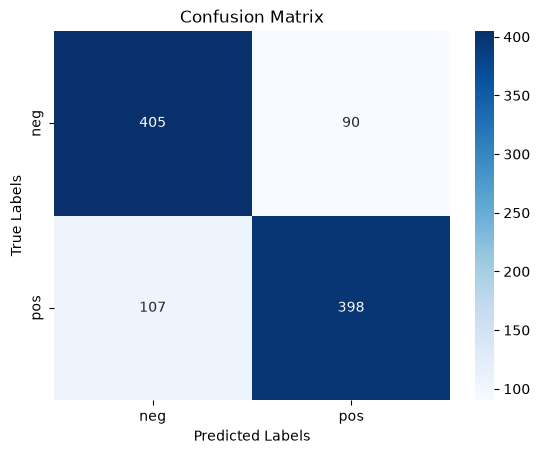

In [90]:
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
sns.heatmap(
    cm, annot=True, fmt='d',
    xticklabels=clf.classes_,
    yticklabels=clf.classes_, cmap='Blues'
)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

**Verification against the book:** Figure 9.10 — `neg` precision 0.791016 / recall 0.818182 / F1 0.804369 (support 495), `pos` 0.815574 / 0.788119 / 0.801611 (505), accuracy 0.803000, macro and weighted averages 0.803 ✔; Figure 9.11 — confusion matrix `[[405, 90], [107, 398]]` ✔ (all reproduced to the digit). Both classes are classified with similar accuracy (recall 0.818 for `neg`, 0.788 for `pos`), as the book says.

### How it works…
Precision, recall, F1 and the confusion matrix are the metrics of Chapter 6:
* **Precision** = TP / (TP + FP): of the reviews predicted `pos`, how many are `pos`;
* **Recall** (sensitivity) = TP / (TP + FN): of the true `pos` reviews, how many were found;
* **F1** = the harmonic mean of the two;
* the **confusion matrix** counts each (true, predicted) pair — the diagonal is correct, the off-diagonal cells are the mistakes.

**Extension — recompute every number from the confusion matrix.** (Treating `pos` as the positive class.)

In [91]:
tn, fp, fn, tp = cm.ravel()
prec_pos, rec_pos = tp / (tp + fp), tp / (tp + fn)
prec_neg, rec_neg = tn / (tn + fn), tn / (tn + fp)
f1_pos = 2 * prec_pos * rec_pos / (prec_pos + rec_pos)
print(f"pos: precision {prec_pos:.6f} recall {rec_pos:.6f} F1 {f1_pos:.6f}   <- classification report: {report_df.loc['pos', ['precision','recall','f1-score']].round(6).tolist()}")
print(f"neg: precision {prec_neg:.6f} recall {rec_neg:.6f}")

support_neg, support_pos = tn + fp, tp + fn
acc = (tn + tp) / cm.sum()
w_prec = (prec_neg * support_neg + prec_pos * support_pos) / cm.sum()
w_rec = (rec_neg * support_neg + rec_pos * support_pos) / cm.sum()
print(f"\nweighted precision {w_prec:.6f} | weighted recall {w_rec:.6f} | accuracy {acc:.6f}")
print("-> the 'weighted' recall printed by the book is identical to accuracy: it is always so (the support-weighted mean of the per-class recalls is (sum of TP_k) / n)")

pos: precision 0.815574 recall 0.788119 F1 0.801611   <- classification report: [0.815574, 0.788119, 0.801611]
neg: precision 0.791016 recall 0.818182

weighted precision 0.803417 | weighted recall 0.803000 | accuracy 0.803000
-> the 'weighted' recall printed by the book is identical to accuracy: it is always so (the support-weighted mean of the per-class recalls is (sum of TP_k) / n)


This identity is a useful sanity check — and a reason not to read "Recall: 0.803" in the book's output as separate evidence from "accuracy 0.803".

**Extension — how precise is "0.803"?** The test set has 1,000 reviews, so the standard error of the accuracy is $\sqrt{0.8\cdot0.2/1000}\approx0.013$, a 95% interval of roughly ±2.5 points. Cross-validation of the whole pipeline (vectoriser included) gives a second opinion, and the ROC curve (the book's "There's more") shows the whole trade-off instead of one threshold:

hold-out accuracy 0.803  ->  95% interval [0.778, 0.828]


5-fold CV accuracy on all 2,000 reviews: [0.815 0.838 0.798 0.83  0.835] | mean 0.823 | std 0.015
ROC AUC: 0.891


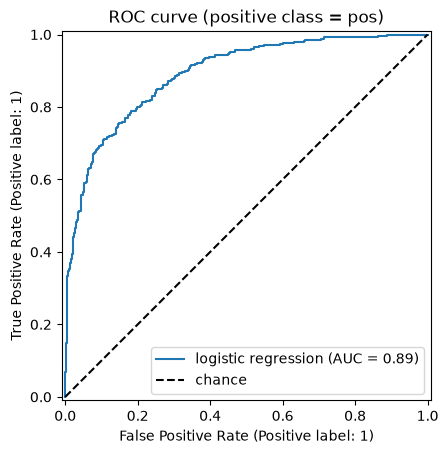

In [92]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, RocCurveDisplay

acc = np.mean(np.array(y_pred) == np.array(y_test))
se = np.sqrt(acc * (1 - acc) / len(y_test))
print(f"hold-out accuracy {acc:.3f}  ->  95% interval [{acc - 1.96*se:.3f}, {acc + 1.96*se:.3f}]")

pipe = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
s = cross_val_score(pipe, np.array(texts, dtype=object), np.array(labels), cv=StratifiedKFold(5, shuffle=True, random_state=2024))
print("5-fold CV accuracy on all 2,000 reviews:", s.round(3), "| mean", round(s.mean(), 3), "| std", round(s.std(), 3))

proba_pos = clf.predict_proba(X_test_vect)[:, 1]
print("ROC AUC:", round(roc_auc_score(np.array(y_test) == "pos", proba_pos), 3))
RocCurveDisplay.from_predictions(np.array(y_test) == "pos", proba_pos, name="logistic regression")
plt.plot([0, 1], [0, 1], "k--", label="chance"); plt.legend(); plt.title("ROC curve (positive class = pos)"); plt.show()

The 95% interval for the hold-out accuracy is **[0.778, 0.828]**; the 5-fold CV on all 2,000 reviews gives 0.823 ± 0.015 (higher than 0.803 because each fold trains on 1,600 reviews instead of 1,000). The **ROC AUC of 0.891** means that a random `pos` review gets a higher positive probability than a random `neg` review 89% of the time.

**Extension — what the model learned, and does more data help?** The largest positive and negative coefficients of the logistic regression, and a learning curve (accuracy vs the number of training reviews, 5-fold CV):

most 'neg' words: bad, movie, this, plot, boring, worst, there, have, no, stupid, supposed, nothing
most 'pos' words: and, is, as, his, life, war, mulan, great, truman, very, of, men


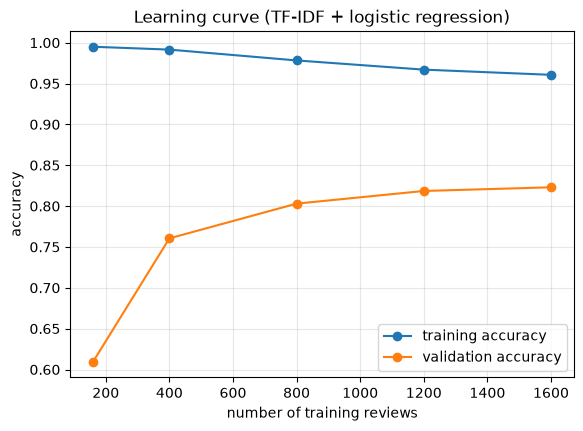

validation accuracy: {160: 0.61, 400: 0.761, 800: 0.803, 1200: 0.818, 1600: 0.823}
training accuracy  : {160: 0.995, 400: 0.992, 800: 0.978, 1200: 0.967, 1600: 0.961}


In [93]:
from sklearn.model_selection import learning_curve

terms = vectorizer.get_feature_names_out()
order = np.argsort(clf.coef_[0])          # coef_[0] is the weight for classes_[1] == 'pos'
print("most 'neg' words:", ", ".join(terms[order[:12]]))
print("most 'pos' words:", ", ".join(terms[order[::-1][:12]]))

sizes, train_sc, val_sc = learning_curve(pipe, np.array(texts, dtype=object), np.array(labels), train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
                                         cv=StratifiedKFold(5, shuffle=True, random_state=2024))
plt.figure(figsize=(6.5, 4.5))
plt.plot(sizes, train_sc.mean(axis=1), "o-", label="training accuracy")
plt.plot(sizes, val_sc.mean(axis=1), "o-", label="validation accuracy")
plt.xlabel("number of training reviews"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=0.3); plt.title("Learning curve (TF-IDF + logistic regression)")
plt.show()
print("validation accuracy:", dict(zip(sizes.tolist(), val_sc.mean(axis=1).round(3).tolist())))
print("training accuracy  :", dict(zip(sizes.tolist(), train_sc.mean(axis=1).round(3).tolist())))

The extremes of the `neg` list are genuine sentiment words (`bad`, `boring`, `worst`, `stupid`, `nothing`) and `great` appears for `pos`, but both lists also contain **non-sentiment tokens** — function words (`this`, `there`, `and`, `is`, `of`; stop words were not removed) and film titles (`mulan`, `truman`) — because 2,000 reviews cover a limited set of films.
The learning curve shows a large gap between training accuracy (0.96–1.00) and validation accuracy: a high-variance model. Validation accuracy rises 0.61 (160 reviews) → 0.76 (400) → 0.80 (800) → 0.82 (1,200) → 0.823 (1,600) — still creeping up, so the book's 1,000-review training set (0.803) is not yet at the plateau, and more labelled data is the cheapest improvement.

### There's more…
ROC curves and AUC (above) summarise a binary classifier across all thresholds; cross-validation (above) averages out the luck of a single split.

### Theory — evaluating text classifiers
* **Accuracy** is misleading with imbalanced classes (Section 4: a classifier that always says `learned` scores 0.16); look at per-class precision/recall/F1.
* **Averaging for multiclass:** *macro* = unweighted mean over classes (rare classes count equally), *weighted* = support-weighted (large classes dominate; weighted recall = accuracy), *micro* = pooled counts (equals accuracy for single-label multiclass).
* **Uncertainty:** with *n* test documents an accuracy has a standard error of about $\sqrt{p(1-p)/n}$; differences of a couple of points are not evidence unless *n* is large or the comparison is repeated (CV).
* **Leakage:** fit the vectoriser inside the training fold (a `Pipeline`) so the vocabulary and IDF values never see the test documents.

### Hands-on workflow (book)
Select a text dataset, preprocess it, train a classifier (logistic regression), evaluate it with precision/recall/F1 and a confusion matrix, visualise the metrics and try cross-validation and further metrics — as above.

## 7. Practical exercises in text processing

The book closes with three exercises — **preprocessing and vectorising text**, **feature extraction with n-grams** and **building and evaluating a multiclass classifier** — but only lists the implementation steps (no code). They are implemented here with the corpora already used in the chapter.

### Exercise 1: Preprocessing and vectorizing text
Steps (book): load the libraries, load the dataset, preprocess the data (basic cleaning), vectorise the text. Dataset: the 2,000 movie reviews.

In [94]:
import re
import numpy as np
import pandas as pd
from nltk.corpus import movie_reviews
from sklearn.feature_extraction.text import TfidfVectorizer

# 2. load the dataset
reviews = [movie_reviews.raw(f) for f in movie_reviews.fileids()]
sentiment = [movie_reviews.categories(f)[0] for f in movie_reviews.fileids()]

# 3. basic cleaning: lower-case, drop digits and punctuation, collapse whitespace
def clean(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)     # keep letters only
    return re.sub(r"\s+", " ", text).strip()

cleaned = [clean(t) for t in reviews]
print("BEFORE:", repr(reviews[0][:160]))
print("AFTER :", repr(cleaned[0][:160]))

# 4. vectorise
raw_vec = TfidfVectorizer(min_df=5)
clean_vec = TfidfVectorizer(min_df=5)
X_raw = raw_vec.fit_transform(reviews)
X_clean = clean_vec.fit_transform(cleaned)
print("\nvocabulary (min_df=5): raw text", len(raw_vec.vocabulary_), "| cleaned text", len(clean_vec.vocabulary_))
print("matrix:", X_clean.shape, f"| density {X_clean.nnz / (X_clean.shape[0] * X_clean.shape[1]):.2%}")
removed = sorted(set(raw_vec.vocabulary_) - set(clean_vec.vocabulary_))
added = sorted(set(clean_vec.vocabulary_) - set(raw_vec.vocabulary_))
print(f"terms lost by cleaning: {len(removed)}", removed[:12], "...")
print(f"terms gained (word fragments created by deleting digits/punctuation): {len(added)}", added)

BEFORE: 'plot : two teen couples go to a church party , drink and then drive . \nthey get into an accident . \none of the guys dies , but his girlfriend continues to see h'
AFTER : 'plot two teen couples go to a church party drink and then drive they get into an accident one of the guys dies but his girlfriend continues to see him in her li'



vocabulary (min_df=5): raw text 13319 | cleaned text 13178
matrix: (2000, 13178) | density 2.35%
terms lost by cleaning: 150 ['00', '000', '007', '10', '100', '1000', '101', '102', '105', '11', '12', '13'] ...
terms gained (word fragments created by deleting digits/punctuation): 9 ['ca', 'dragonheart', 'min', 'mm', 'offscreen', 'po', 'th', 'vh', 'ww']


The cleaning changes the vocabulary very little: 150 terms are lost (numbers and tokens containing digits — `000`, `007`, `13th`, `16mm`) and 9 word *fragments* appear (`th`, `mm`, `ww`, …), net 13,319 → 13,178. `movie_reviews.raw` is already lower-cased and tokenised with spaces around punctuation, and `CountVectorizer`'s default pattern ignores punctuation anyway, so the book's "basic cleaning" has almost nothing to do on this corpus; on raw web or e-mail text (mixed case, HTML, URLs) it matters far more. Whether deleting digits is wise (a year such as `1999` can be informative) is an empirical question.

### Exercise 2: Feature extraction with n-grams
Steps (book): load the libraries, load the dataset, extract n-gram features. Besides counting them, look at which n-grams the sentiment model finds most informative (no stop-word removal, so phrases like *waste of time* survive):

In [95]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

ng = TfidfVectorizer(ngram_range=(1, 3), min_df=5)
X_ng = ng.fit_transform(cleaned)
names = ng.get_feature_names_out()
n_words = np.array([len(n.split()) for n in names])
print("features for ngram_range=(1,3), min_df=5:", X_ng.shape[1], "->", {k: int((n_words == k).sum()) for k in (1, 2, 3)})

lr = LogisticRegression(max_iter=1000).fit(X_ng, sentiment)       # coef_[0]: positive class = 'pos'
order = np.argsort(lr.coef_[0])
multi = [i for i in order if n_words[i] > 1]
print("\nstrongest 'neg' n-grams (2-3 words):", [names[i] for i in multi[:10]])
print("strongest 'pos' n-grams (2-3 words):", [names[i] for i in multi[::-1][:10]])

features for ngram_range=(1,3), min_df=5: 59625 -> {1: 13178, 2: 32080, 3: 14367}



strongest 'neg' n-grams (2-3 words): ['the worst', 'to be', 'have been', 'supposed to', 'should have', 'the only', 'at least', 'could have', 'waste of', 'the plot']
strongest 'pos' n-grams (2-3 words): ['he is', 'the best', 'of the best', 'as the', 'to the', 'of the', 'is very', 'one of', 'pulp fiction', 'is great']


Of the 59,625 features, 13,178 are unigrams, 32,080 bigrams and 14,367 trigrams. Some of the strongest n-grams are real sentiment phrases (`the worst`, `waste of`, `the best`, `is great`, `is very`), and `supposed to`, `should have`, `could have` are typical markers of disappointment. Others are incidental (`pulp fiction`, `he is`, `of the`): fitted on only 2,000 reviews, the coefficients also describe *this corpus* (the films it contains), not English. (This model is fitted on all 2,000 reviews to inspect it, not to evaluate it.)

### Exercise 3: Building and evaluating a multiclass classifier
Steps (book): load the libraries, load the dataset, vectorise, split, train the classifier, predict and evaluate. Dataset: Reuters stories that carry **exactly one** of the 8 most frequent topics (a genuine single-label multiclass problem, unlike the first-category shortcut).

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import reuters
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

ids = reuters.fileids()
topic_counts = pd.Series([c for d in ids for c in reuters.categories(d)]).value_counts()
top8 = list(topic_counts.head(8).index)
single = [d for d in ids if len(reuters.categories(d)) == 1 and reuters.categories(d)[0] in top8]
texts = [reuters.raw(d) for d in single]
labels = [reuters.categories(d)[0] for d in single]
print("top-8 topics:", top8)
print("single-label stories in those topics:", len(single), "|", pd.Series(labels).value_counts().to_dict())

# 3-4. vectorise and split (the vectoriser is fitted on the training part only)
X_tr, X_te, y_tr, y_te = train_test_split(texts, labels, test_size=0.3, stratify=labels, random_state=2024)
vec = TfidfVectorizer(stop_words='english', min_df=2)
A, B = vec.fit_transform(X_tr), vec.transform(X_te)

# 5-6. train, predict, evaluate
for C in (1, 10):
    clf = LogisticRegression(C=C, max_iter=2000).fit(A, y_tr)
    print(f"C={C:>2}: test accuracy {accuracy_score(y_te, clf.predict(B)):.3f}")

top-8 topics: ['earn', 'acq', 'money-fx', 'grain', 'crude', 'trade', 'interest', 'ship']
single-label stories in those topics: 7691 | {'earn': 3923, 'acq': 2292, 'crude': 374, 'trade': 326, 'money-fx': 309, 'interest': 272, 'ship': 144, 'grain': 51}


C= 1: test accuracy 0.948


C=10: test accuracy 0.964


              precision    recall  f1-score   support

         acq      0.933     0.996     0.963       688
       crude      0.990     0.920     0.954       112
        earn      0.986     0.981     0.984      1177
       grain      1.000     0.667     0.800        15
    interest      0.920     0.841     0.879        82
    money-fx      0.914     0.796     0.851        93
        ship      0.974     0.884     0.927        43
       trade      0.968     0.929     0.948        98

    accuracy                          0.964      2308
   macro avg      0.961     0.877     0.913      2308
weighted avg      0.965     0.964     0.963      2308



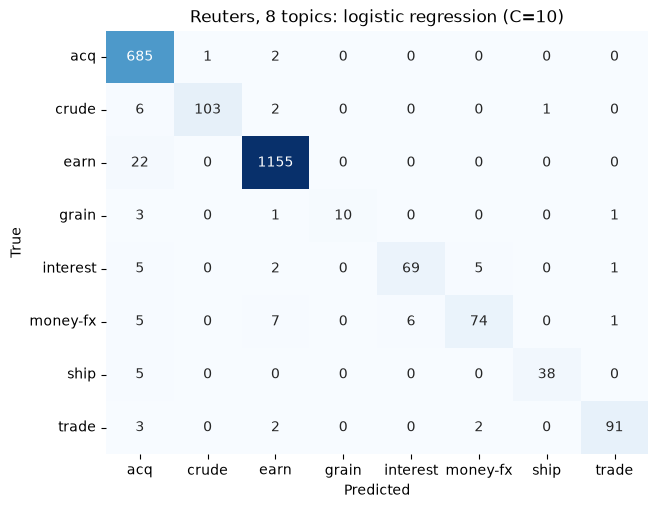

In [97]:
clf = LogisticRegression(C=10, max_iter=2000).fit(A, y_tr)
y_hat = clf.predict(B)
print(classification_report(y_te, y_hat, digits=3))
cm = confusion_matrix(y_te, y_hat, labels=clf.classes_)
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clf.classes_, yticklabels=clf.classes_, cbar=False)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Reuters, 8 topics: logistic regression (C=10)'); plt.show()

On 2,308 test stories the accuracy is **0.948** with the default `C=1` and **0.964** with `C=10`, against a majority-class baseline of 0.510 (`earn`: 1,177 of 2,308). Unlike the Brown genres, Reuters topics have distinctive keywords, so the same algorithm works well from the start.
The per-class report shows the cost of imbalance: the smallest classes have the lowest recall (`grain` 0.667 — only 15 test stories —, `money-fx` 0.796, `interest` 0.841) while precision stays high. The confusion matrix shows where the mistakes go: 49 of the 83 errors are predicted as `acq`, the second-largest class (22 of them true `earn` stories) — an imbalanced classifier drifts towards the large classes.

## Chapter takeaways
1. **Text must become numbers.** `CountVectorizer` builds a sparse document-term matrix of counts (Bag of Words); `TfidfVectorizer` re-weights it so that words frequent in a document but rare in the corpus stand out, with every row L2-normalised. Always fit the vectoriser on the training data only (put it in a `Pipeline`) and keep the matrix sparse (4.7 MB vs 987 MB for Reuters).
2. **Vocabulary choices are hyper-parameters.** Stop words, `min_df`, stemming and n-grams change the feature space — `min_df=2` halved the movie-review vocabulary and stemming cut it by 31% — but on movie reviews they moved accuracy by ≤ 1 point (n-grams even lowered it). Negations are in the stop-word list.
3. **n-grams, POS tags and NER add structure** (phrases, grammar, entities) at a cost: 40k → 540k → 1.5M features. NER needs a trained model; the book mentions it but shows no code.
4. **Defaults can under-fit TF-IDF.** On Brown, default Naive Bayes, SVM and logistic regression use only 2–7 of 15 classes (0.23–0.33 accuracy); tuning `alpha` or `C` roughly doubles every model to ≈ 0.5, and the three then tie. The ranking in the book's Figure 9.7 mostly ranks mis-scaled defaults.
5. **OvR vs OvO:** OvR needs *k* models, OvO *k(k–1)/2* models on small pair-wise subsets. OvR wins 10/10 splits at default `C`; at `C=100` they tie. OvO's real benefit is speed with kernel methods. Multiclass (one label) differs from multilabel (several labels, OvR + Hamming loss / micro-F1).
6. **Evaluate with care:** weighted recall equals accuracy; a 1,000-document test set gives ±2.5 points of uncertainty; cross-validate the whole pipeline; learning curves show whether more data would help (they do here: 0.61 → 0.82 from 160 to 1,600 reviews).

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| Fig. 9.1 code | `barh` of the vocabulary, "top 20 tokens" | the printed code draws all **18,881** bars; the figure needs a top-20 selection; `plt` not imported |
| Reuters description | "≈ 1.3 million words, over 90 topics" | **1,720,901** words; exactly **90** categories (79 occur as a first category); 1,628 documents have several categories |
| Fig. 9.2 interpretation | tokens "sorted by … distinctiveness" | mean TF-IDF over all documents: ranks the jargon of the largest class (`earn`), not class-distinguishing words |
| POS bigram code/output | listing shows spaces between tagged tokens; no `.`; trailing single-token lines | the f-strings are concatenated without a space; the tagger also tags `.`; the code cannot print single-token lines |
| NER | "we'll demonstrate n-grams, POS tagging, and NER" | no NER code anywhere in the recipe (only spaCy in the exercise list) |
| NLTK API | `except nltk.downloader.DownloadError` | that class does not exist in NLTK 3.10.3; `nltk.data.find` raises `LookupError`; `punkt` is legacy (`punkt_tab`) |
| Brown comment | "minimum number of samples per category is > 20" | `science_fiction` has 6, `humor` 9, `reviews`/`religion` 17 |
| Naive Bayes claim | "performs well on text data" | it is the *worst* model in Fig. 9.7 (0.228, 2 of 15 classes); `alpha=1` is mis-scaled for TF-IDF (0.504 with `alpha=0.001`) |
| Model comparison | "highly differentiated" performance across models | all three under-fit (7–17 points above a 0.16 baseline); tuned, they tie at ≈ 0.5 |
| Logistic regression | "useful for binary classification" in a 15-class example | it handles multiclass natively (softmax); the sentence is out of place |
| Multiclass recipe comments | "6 documents in brown"; "filename as label"; NLTK quote about Firefox forum, Pirates of the Caribbean, wine reviews | 500 documents; label = genre; the quote describes the `webtext` corpus, not Brown |
| Multiclass intro | "multiple labels or multiple labels per inference" (duplicated) | conflates multiclass with **multilabel** (different problem; demonstrated on Reuters) |
| Figs. 9.8 / 9.9 | produced by the printed code | printed split (`test_size=0.5`, no stratify) gives 250 test docs, 0.272 / 0.264; the figures need `test_size=0.3, stratify=labels` (150 docs, 0.307 / 0.273) |
| `brown.raw` | used as plain text | contains `word/TAG` tokens, so POS-tag fragments become features (Recipe 4 used `brown.words`) |
| "romance" remark | "romance did not elicit any predictive performance compared to OvO" | reversed: OvR F1 = 0.316 on `romance`, **OvO = 0** |
| OvO vs OvR | OvO "often better on balanced datasets"; OvR "slightly edges out" OvO | the data is unbalanced; OvR wins 10/10 at `C=1` but they tie at `C=100`; OvO is mainly for speed with kernel methods |
| Weighted recall | shown as evidence next to accuracy (0.803 / 0.803) | weighted recall is always identical to accuracy |
| `random.shuffle` | needed "for better splitting" | redundant: `train_test_split` shuffles |
| Imports | `plt`, `train_test_split`, `pd`, `TfidfVectorizer`, `classification_report` missing in some recipes | added |

*Chapters 1–9 are complete.*